# Day 18 — Python Packaging & Reusable DS Modules

**Fase 1 — Python Basics · Dia 18/28 · 31/10/2026 · 🏁 Último dia da Fase 1**

Hoje eu fecho a Fase 1 transformando código solto de notebook em **pacotes Python reutilizáveis**: módulos organizados, um `pyproject.toml` completo, interfaces de linha de comando (CLIs), testes, instalação editável e build de *wheels*.

### Objetivos de aprendizagem
- Entender a diferença entre **módulo**, **pacote** e **subpacote** (`__init__.py`, `__all__`, imports relativos).
- Ler e escrever um `pyproject.toml` moderno: `[build-system]`, `[project]`, `[project.scripts]`, extras e configuração de ferramentas.
- Construir um mini pacote de DS (`dskit`) com `data_loader`, `preprocessor` e `visualizer`, usando **dados reais**.
- Criar CLIs com `argparse` (biblioteca padrão) e com **Click** (decorators).
- Testar o pacote com `pytest`, instalar em modo editável (`pip install -e .`) num *venv* real e gerar *sdist*/*wheel* com `python -m build`.
- Empacotar um mini pacote de NLP educacional (`nlp_edu`) e aplicá-lo ao **corpus Gutenberg do NLTK**.

### Datasets reais usados
- `seaborn.load_dataset`: `titanic`, `penguins`, `tips`
- `nltk.corpus.gutenberg`: textos de domínio público (Carroll, Austen, Melville, Burgess, Bryant, Chesterton, Shakespeare)

> ⚠️ **Nota:** todos os pacotes são escritos num **diretório temporário** criado pelo próprio notebook — nada é instalado no ambiente do kernel. O *venv* da Seção 6 também é temporário e isolado.

## Introdução — por que empacotar importa em Data Science?

Um notebook é ótimo para **explorar**, mas péssimo para **reutilizar**. Quando a mesma função de limpeza aparece copiada em 5 notebooks, cada cópia evolui de um jeito e os bugs se multiplicam. Empacotar resolve isso:

| Problema no notebook | O que o pacote oferece |
| --- | --- |
| Funções copiadas e coladas | **Uma única fonte de verdade**, importável em qualquer lugar |
| "Funciona na minha máquina" | Dependências declaradas no `pyproject.toml` |
| Código difícil de testar | Módulos pequenos + `pytest` |
| Análises que só rodam no Jupyter | **CLIs** que rodam em scripts, cron, CI ou Docker |
| Deploy manual | `wheel` instalável com `pip install` |

Em produção, o fluxo típico é: **explorar no notebook → extrair funções para um pacote → testar → expor via CLI/API → distribuir**. É exatamente esse caminho que eu percorro hoje.

In [1]:
from __future__ import annotations

import importlib
import importlib.metadata
import json
import os
import pkgutil
import subprocess
import sys
import tarfile
import tempfile
import textwrap
import tomllib
import venv
import zipfile
from pathlib import Path

import click
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

# Everything is written to a throw-away workspace: nothing is installed in the kernel env.
WORKSPACE = Path(tempfile.mkdtemp(prefix="day18_packaging_"))
PROJECT = WORKSPACE / "dskit-project"   # project root (holds pyproject.toml)
SRC = PROJECT / "src"                   # "src layout": importable code lives under src/
PY = sys.executable

print(f"Python      : {sys.version.split()[0]}")
print(f"pandas      : {pd.__version__}")
print(f"seaborn     : {sns.__version__}")
print(f"click       : {importlib.metadata.version('click')}")
print(f"Workspace   : {WORKSPACE.name} (temporary directory)")

Python      : 3.11.17
pandas      : 2.3.3
seaborn     : 0.13.2
click       : 8.5.0
Workspace   : day18_packaging_c5qyngdv (temporary directory)


In [2]:
def write_module(relative_path: str, source: str, root: Path = SRC) -> Path:
    """Write ``source`` (dedented) to ``root / relative_path``, creating parent folders."""
    path = root / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(textwrap.dedent(source).lstrip(), encoding="utf-8")
    return path


IGNORED = {"__pycache__", ".pytest_cache", "build", ".venv"}  # .venv: thousands of files


def show_tree(root: Path, prefix: str = "") -> None:
    """Print a directory tree (like the Unix ``tree`` command), skipping build artefacts."""
    if not prefix:
        print(f"{root.name}/")
    entries = sorted(
        (p for p in root.iterdir() if p.name not in IGNORED and not p.name.endswith(".egg-info")),
        key=lambda p: (p.is_file(), p.name),
    )
    for i, entry in enumerate(entries):
        last = i == len(entries) - 1
        print(f"{prefix}{'└── ' if last else '├── '}{entry.name}{'/' if entry.is_dir() else ''}")
        if entry.is_dir():
            show_tree(entry, prefix + ("    " if last else "│   "))


def run(cmd: list[str], cwd: Path = PROJECT, pythonpath: bool | Path = True,
        check: bool = True, max_lines: int | None = None) -> subprocess.CompletedProcess:
    """Run a shell command, echo it in a readable form and print its output.

    ``pythonpath=True`` exposes ``src/`` without installing the package, which mimics
    running the code from a cloned repository; a Path exposes that folder instead and
    ``False`` hides every uninstalled package.
    """
    env = {**os.environ, "MPLBACKEND": "Agg", "PIP_DISABLE_PIP_VERSION_CHECK": "1"}
    env.pop("PYTHONPATH", None)
    if pythonpath:
        env["PYTHONPATH"] = str(SRC if pythonpath is True else pythonpath)
    shown = " ".join("python" if c == PY else Path(c).name if c.startswith(str(WORKSPACE)) else c
                     for c in map(str, cmd))
    print(f"$ {shown}")
    result = subprocess.run(list(map(str, cmd)), cwd=cwd, env=env, capture_output=True, text=True)
    output = (result.stdout + result.stderr).rstrip()
    lines = output.splitlines()
    if max_lines and len(lines) > max_lines:
        lines = lines[:max_lines] + [f"... ({len(output.splitlines()) - max_lines} more lines)"]
    print("\n".join(lines))
    print(f"[exit code: {result.returncode}]\n")
    if check and result.returncode != 0:
        raise RuntimeError(f"Command failed with exit code {result.returncode}")
    return result

## Seção 1 — Estrutura de módulos Python: `__init__.py`, submódulos e `__all__`

Conceitos-chave:

- **Módulo**: qualquer arquivo `.py` (ex.: `counting.py`).
- **Pacote**: uma pasta com `__init__.py`. O `__init__.py` roda **na primeira importação** e define a "fachada" pública do pacote.
- **Subpacote**: um pacote dentro de outro (ex.: `minipkg/metrics/`).
- **`__all__`**: lista dos nomes exportados por `from pacote import *`. Também documenta a **API pública** — ferramentas como IDEs, `pydoc` e linters respeitam essa lista.
- **Convenção `_privado`**: nomes com underscore inicial são detalhes internos; não fazem parte do contrato público.
- **Imports relativos** (`from .counting import ...`, `from ..counting import ...`) só funcionam *dentro* de pacotes e deixam o código independente do nome da pasta-raiz.

Vou criar um pacote didático, `minipkg`, com um subpacote `metrics`.

In [3]:
SECTION1 = WORKSPACE / "section1"

write_module("minipkg/_version.py", '''
    """Single source of truth for the package version."""
    __version__ = "0.0.1"
''', root=SECTION1)

write_module("minipkg/counting.py", '''
    """Counting helpers for categorical columns (works on any iterable)."""
    from __future__ import annotations

    from collections import Counter
    from collections.abc import Hashable, Iterable

    __all__ = ["frequency_table", "value_share"]


    def _normalise(values: Iterable[Hashable]) -> list[Hashable]:
        """Private helper: drop None and NaN (NaN is the only value where v != v)."""
        return [v for v in values if v is not None and v == v]


    def frequency_table(values: Iterable[Hashable]) -> list[tuple[Hashable, int]]:
        """Return (value, count) pairs sorted from most to least frequent."""
        return Counter(_normalise(values)).most_common()


    def value_share(values: Iterable[Hashable], decimals: int = 3) -> dict[Hashable, float]:
        """Return the relative frequency of each value, ignoring missing data."""
        clean = _normalise(values)
        if not clean:
            raise ValueError("value_share() needs at least one non-missing value")
        return {k: round(n / len(clean), decimals) for k, n in Counter(clean).most_common()}


    def debug_counts(values: Iterable[Hashable]) -> str:
        """Public-looking helper deliberately left out of __all__."""
        return f"{len(_normalise(values))} valid values"
''', root=SECTION1)

write_module("minipkg/metrics/__init__.py", '''
    """Sub-package with dispersion metrics."""
    from .spread import coefficient_of_variation, iqr

    __all__ = ["iqr", "coefficient_of_variation"]
''', root=SECTION1)

write_module("minipkg/metrics/spread.py", '''
    """Dispersion metrics built on the standard library only."""
    from __future__ import annotations

    import statistics
    from collections.abc import Iterable

    from ..counting import _normalise  # relative import from the parent package

    __all__ = ["iqr", "coefficient_of_variation"]


    def iqr(values: Iterable[float]) -> float:
        """Interquartile range (Q3 - Q1) using the 'inclusive' quantile method."""
        q1, _, q3 = statistics.quantiles(_normalise(values), n=4, method="inclusive")
        return q3 - q1


    def coefficient_of_variation(values: Iterable[float]) -> float:
        """Sample standard deviation divided by the mean."""
        clean = _normalise(values)
        return statistics.stdev(clean) / statistics.fmean(clean)
''', root=SECTION1)

write_module("minipkg/__init__.py", '''
    """minipkg - a tiny package used to study imports, __init__.py and __all__."""
    from ._version import __version__
    from .counting import frequency_table, value_share

    __all__ = ["frequency_table", "value_share", "__version__"]
''', root=SECTION1)

show_tree(SECTION1 / "minipkg")

minipkg/
├── metrics/
│   ├── __init__.py
│   └── spread.py
├── __init__.py
├── _version.py
└── counting.py


In [4]:
# Make the folder that *contains* the package importable, then import it.
sys.path.insert(0, str(SECTION1))
import minipkg  # noqa: E402
from minipkg import metrics  # noqa: E402

print("minipkg.__version__ :", minipkg.__version__)
print("minipkg.__all__     :", minipkg.__all__)
print("minipkg.__file__    :", Path(minipkg.__file__).relative_to(WORKSPACE))
print("minipkg.__path__    :", [Path(p).name for p in minipkg.__path__], "(only packages have __path__)")

# What does a star-import actually bring in? Run it in an isolated namespace.
namespace: dict = {}
exec("from minipkg import *", namespace)
print("\nfrom minipkg import *          ->", sorted(k for k in namespace if not k.startswith("__builtins")))
namespace = {}
exec("from minipkg.counting import *", namespace)
print("from minipkg.counting import * ->", sorted(k for k in namespace if not k.startswith("__builtins")))
print("debug_counts still reachable explicitly:", minipkg.counting.debug_counts([1, None, 2]))

minipkg.__version__ : 0.0.1
minipkg.__all__     : ['frequency_table', 'value_share', '__version__']
minipkg.__file__    : section1/minipkg/__init__.py
minipkg.__path__    : ['minipkg'] (only packages have __path__)

from minipkg import *          -> ['__version__', 'frequency_table', 'value_share']
from minipkg.counting import * -> ['frequency_table', 'value_share']
debug_counts still reachable explicitly: 2 valid values


In [5]:
# Apply the package to real data: Palmer penguins (seaborn built-in dataset).
penguins = sns.load_dataset("penguins")

print("Species share     :", minipkg.value_share(penguins["species"]))
print("Island frequencies:", minipkg.frequency_table(penguins["island"]))
for col in ["bill_length_mm", "flipper_length_mm", "body_mass_g"]:
    print(f"{col:<18} IQR = {metrics.iqr(penguins[col]):8.2f} | CV = {metrics.coefficient_of_variation(penguins[col]):.3f}")

# Sanity check against pandas (same 'inclusive' = linear interpolation definition).
q = penguins["body_mass_g"].quantile([0.25, 0.75])
assert abs((q[0.75] - q[0.25]) - metrics.iqr(penguins["body_mass_g"])) < 1e-9
print("\n✅ minipkg.metrics.iqr matches pandas.quantile")

Species share     : {'Adelie': 0.442, 'Gentoo': 0.36, 'Chinstrap': 0.198}
Island frequencies: [('Biscoe', 168), ('Dream', 124), ('Torgersen', 52)]
bill_length_mm     IQR =     9.27 | CV = 0.124
flipper_length_mm  IQR =    23.00 | CV = 0.070
body_mass_g        IQR =  1200.00 | CV = 0.191

✅ minipkg.metrics.iqr matches pandas.quantile


### Como o Python encontra e cacheia módulos

- O Python procura pacotes nas pastas de `sys.path` (diretório atual, `site-packages`, `PYTHONPATH`...).
- Depois da primeira importação, o módulo fica em **`sys.modules`** — importar de novo **não** reexecuta o arquivo. Para recarregar após editar, usa-se `importlib.reload` (útil em notebooks, mas não é solução de produção).
- `pkgutil.walk_packages` lista todos os submódulos de um pacote — é assim que frameworks descobrem *plugins*.

In [6]:
print("Loaded minipkg modules:", sorted(m for m in sys.modules if m.startswith("minipkg")))

print("\nDiscovered via pkgutil.walk_packages:")
for info in pkgutil.walk_packages(minipkg.__path__, prefix="minipkg."):
    print(f"  {'package' if info.ispkg else 'module ':<8} {info.name}")

# Editing a file is NOT seen until reload: demonstrate with the version string.
version_file = SECTION1 / "minipkg" / "_version.py"
version_file.write_text('__version__ = "0.0.2"\n', encoding="utf-8")
print("\nAfter editing, without reload:", sys.modules["minipkg._version"].__version__)
importlib.reload(sys.modules["minipkg._version"])
importlib.reload(minipkg)
print("After importlib.reload        :", minipkg.__version__)

Loaded minipkg modules: ['minipkg', 'minipkg._version', 'minipkg.counting', 'minipkg.metrics', 'minipkg.metrics.spread']

Discovered via pkgutil.walk_packages:
  module   minipkg._version
  module   minipkg.counting
  package  minipkg.metrics
  module   minipkg.metrics.spread

After editing, without reload: 0.0.1
After importlib.reload        : 0.0.2


## Seção 2 — Anatomia do `pyproject.toml`

O `pyproject.toml` (PEP 518/621) é **o** arquivo de configuração de um projeto Python moderno. Ele substitui `setup.py`, `setup.cfg` e boa parte dos arquivos de configuração de ferramentas.

| Tabela | Para que serve |
| --- | --- |
| `[build-system]` | Diz ao `pip`/`build` **qual backend** compila o pacote (setuptools, hatchling, flit, poetry-core...). |
| `[project]` | Metadados padronizados (PEP 621): nome, versão, dependências, versão do Python, autores, licença. |
| `[project.optional-dependencies]` | *Extras* instaláveis sob demanda: `pip install "dskit[dev]"`. |
| `[project.scripts]` | **Entry points de console**: o `pip` cria um executável `dskit` que chama `dskit.cli_click:cli`. |
| `[project.urls]` | Links exibidos no PyPI. |
| `[tool.*]` | Configuração de ferramentas (setuptools, pytest, ruff, mypy...). |

> No Dia 15 eu usei o `pyproject.toml` para **gerenciar ambientes e dependências**; hoje o foco é o lado do **empacotamento**: build backend, layout `src/` e entry points.

In [7]:
PYPROJECT = r'''
# =====================================================================
# [build-system] - HOW to build. Read first by pip and `python -m build`.
# =====================================================================
[build-system]
requires = ["setuptools>=77"]            # packages needed *to build* (not to run)
build-backend = "setuptools.build_meta"  # PEP 517 hook object

# =====================================================================
# [project] - WHAT is being distributed (PEP 621 core metadata)
# =====================================================================
[project]
name = "dskit"                           # distribution name on PyPI (pip install dskit)
version = "0.1.0"                        # PEP 440 version
description = "Reusable data-science utilities: loading, preprocessing, plotting and CLIs."
readme = "README.md"                     # becomes the long description on PyPI
requires-python = ">=3.10"               # pip refuses to install on older interpreters
license = "MIT"                          # SPDX expression (PEP 639)
authors = [{ name = "Gutemberg Raposo" }]
keywords = ["data-science", "pandas", "cli", "education"]
classifiers = [
    "Programming Language :: Python :: 3",
    "Intended Audience :: Science/Research",
    "Topic :: Scientific/Engineering :: Information Analysis",
]
# Runtime dependencies: lower bounds, NOT pins (pins belong in lock files).
dependencies = [
    "pandas>=2.0",
    "seaborn>=0.13",
    "matplotlib>=3.7",
    "click>=8.1",
]

# Optional extras: pip install "dskit[dev]"
[project.optional-dependencies]
dev = ["pytest>=8", "build>=1.0"]

# Console entry points: pip generates executables that call these functions.
[project.scripts]
dskit = "dskit.cli_click:main"           # modern Click CLI
dskit-argparse = "dskit.cli:main"        # standard-library argparse CLI

[project.urls]
Repository = "https://github.com/Gutembergfox/Portfolio"

# =====================================================================
# [tool.*] - configuration for individual tools
# =====================================================================
[tool.setuptools.packages.find]
where = ["src"]                          # src layout: packages live in src/

[tool.setuptools.package-data]
dskit = ["py.typed"]                     # ship the PEP 561 typing marker

[tool.pytest.ini_options]
testpaths = ["tests"]
addopts = "-q"
'''

PROJECT.mkdir(parents=True, exist_ok=True)
(PROJECT / "pyproject.toml").write_text(PYPROJECT.lstrip(), encoding="utf-8")
print(f"pyproject.toml written: {len(PYPROJECT.splitlines())} lines")

pyproject.toml written: 57 lines


In [8]:
# Parse it back with the standard-library TOML parser (Python 3.11+) and validate it.
config = tomllib.loads((PROJECT / "pyproject.toml").read_text(encoding="utf-8"))

print("Top-level tables:", list(config))
print("Build backend   :", config["build-system"]["build-backend"])
print("Name / version  :", config["project"]["name"], config["project"]["version"])
print("Dependencies    :", config["project"]["dependencies"])
print("Extras          :", config["project"]["optional-dependencies"])
print("Tool sections   :", sorted(config["tool"]))

entry_points = pd.DataFrame(
    [(cmd, *target.split(":")) for cmd, target in config["project"]["scripts"].items()],
    columns=["console command", "module", "callable"],
)
display(entry_points)

REQUIRED = {"name", "version", "requires-python", "dependencies"}
missing = REQUIRED - config["project"].keys()
assert not missing, f"pyproject.toml is missing {missing}"
print("✅ Required [project] keys present:", sorted(REQUIRED))

Top-level tables: ['build-system', 'project', 'tool']
Build backend   : setuptools.build_meta
Name / version  : dskit 0.1.0
Dependencies    : ['pandas>=2.0', 'seaborn>=0.13', 'matplotlib>=3.7', 'click>=8.1']
Extras          : {'dev': ['pytest>=8', 'build>=1.0']}
Tool sections   : ['pytest', 'setuptools']


,console command,module,callable
0,dskit,dskit.cli_click,main
1,dskit-argparse,dskit.cli,main


✅ Required [project] keys present: ['dependencies', 'name', 'requires-python', 'version']


### Layout `src/` × layout "flat"

```
flat layout                 src layout (usado aqui)
-----------                 -----------------------
projeto/                    projeto/
├── dskit/                  ├── src/
│   └── __init__.py         │   └── dskit/
├── tests/                  │       └── __init__.py
└── pyproject.toml          ├── tests/
                            └── pyproject.toml
```

Com o **layout `src/`**, os testes **não conseguem** importar o pacote "por acidente" a partir da pasta atual: eles precisam do pacote instalado (ou de `PYTHONPATH=src`). Isso garante que eu testo exatamente o que será distribuído — por isso é a recomendação atual da *Python Packaging Authority*.

## Seção 3 — Construindo utilitários reutilizáveis de DS

Agora o pacote real, `dskit`, com três módulos de responsabilidade única:

| Módulo | Responsabilidade | Princípio |
| --- | --- | --- |
| `data_loader.py` | Carregar e validar datasets públicos, com cache | Falhar cedo com mensagens claras |
| `preprocessor.py` | Limpeza, imputação e *one-hot encoding* com `fit`/`transform` | Aprender só no treino, aplicar no teste |
| `visualizer.py` | Gráficos padronizados que **retornam** a `Figure` | Funções testáveis, sem `plt.show()` interno |

In [9]:
write_module("dskit/_version.py", '''
    """Single source of truth for the runtime version string."""
    __version__ = "0.1.0"
''')

write_module("dskit/data_loader.py", '''
    """Load and validate public seaborn datasets with a small in-process cache."""
    from __future__ import annotations

    from functools import lru_cache

    import pandas as pd
    import seaborn as sns

    __all__ = ["SUPPORTED_DATASETS", "load", "dataset_summary"]

    SUPPORTED_DATASETS: dict[str, str] = {
        "titanic": "Passenger survival on the RMS Titanic.",
        "penguins": "Palmer Archipelago penguin measurements.",
        "tips": "Restaurant bills and tips recorded by one waiter.",
        "mpg": "Fuel consumption of 1970-1982 car models.",
    }


    @lru_cache(maxsize=None)
    def _load_cached(name: str) -> pd.DataFrame:
        """Download (first call) or read seaborn's local cache (later calls)."""
        return sns.load_dataset(name)


    def load(name: str, *, columns: list[str] | tuple[str, ...] | None = None,
             dropna: bool = False) -> pd.DataFrame:
        """Return a fresh copy of a supported dataset.

        Args:
            name: Dataset name (case-insensitive), one of ``SUPPORTED_DATASETS``.
            columns: Optional subset of columns to keep.
            dropna: Drop rows with any missing value *after* column selection.

        Raises:
            ValueError: unknown dataset name.
            KeyError: requested columns that do not exist.
        """
        key = name.strip().lower()
        if key not in SUPPORTED_DATASETS:
            raise ValueError(f"Unknown dataset {name!r}. Choose one of {sorted(SUPPORTED_DATASETS)}")
        df = _load_cached(key).copy()  # copy: callers can never corrupt the cache
        if columns:
            unknown = sorted(set(columns) - set(df.columns))
            if unknown:
                raise KeyError(f"Columns not found in {key!r}: {unknown}")
            df = df[list(columns)]
        if dropna:
            df = df.dropna()
        return df.reset_index(drop=True)


    def dataset_summary(df: pd.DataFrame) -> pd.DataFrame:
        """One row per column: dtype, missing values and cardinality."""
        return pd.DataFrame({
            "dtype": df.dtypes.astype(str),
            "n_missing": df.isna().sum(),
            "pct_missing": (df.isna().mean() * 100).round(2),
            "n_unique": df.nunique(),
        })
''')
print("data_loader.py written")

data_loader.py written


In [10]:
write_module("dskit/preprocessor.py", r'''
    """Composable preprocessing helpers with a scikit-learn-like fit/transform API."""
    from __future__ import annotations

    import re
    from dataclasses import dataclass, field

    import pandas as pd

    __all__ = ["clean_column_names", "drop_sparse_columns", "TabularPreprocessor"]


    def _to_snake(name: object) -> str:
        text = re.sub(r"(?<=[a-z0-9])(?=[A-Z])", "_", str(name))
        return re.sub(r"[^0-9a-zA-Z]+", "_", text).strip("_").lower()


    def clean_column_names(df: pd.DataFrame) -> pd.DataFrame:
        """Return a copy with snake_case column names ("Body Mass (g)" -> "body_mass_g")."""
        return df.rename(columns=_to_snake)


    def drop_sparse_columns(df: pd.DataFrame, max_missing: float = 0.5) -> pd.DataFrame:
        """Drop columns whose share of missing values is above ``max_missing``."""
        if not 0.0 <= max_missing <= 1.0:
            raise ValueError("max_missing must be between 0 and 1")
        return df.loc[:, df.isna().mean() <= max_missing]


    @dataclass
    class TabularPreprocessor:
        """Median/mode imputation + one-hot encoding learned on training data only.

        Attributes ending in ``_`` are learned during :meth:`fit` (scikit-learn convention).
        """

        max_missing: float = 0.5
        one_hot: bool = True
        columns_: list[str] = field(default_factory=list, init=False)
        numeric_fill_: dict[str, float] = field(default_factory=dict, init=False, repr=False)
        categorical_fill_: dict[str, object] = field(default_factory=dict, init=False, repr=False)
        output_columns_: list[str] = field(default_factory=list, init=False, repr=False)

        def fit(self, df: pd.DataFrame) -> "TabularPreprocessor":
            data = drop_sparse_columns(clean_column_names(df), self.max_missing)
            self.columns_ = list(data.columns)
            numeric = data.select_dtypes(include="number").columns
            self.numeric_fill_ = {c: float(data[c].median()) for c in numeric}
            self.categorical_fill_ = {}
            for c in data.columns.difference(numeric):
                mode = data[c].mode(dropna=True)
                self.categorical_fill_[c] = mode.iloc[0] if not mode.empty else "missing"
            self.output_columns_ = list(self._encode(self._impute(data)).columns)
            return self

        def transform(self, df: pd.DataFrame) -> pd.DataFrame:
            if not self.columns_:
                raise RuntimeError("TabularPreprocessor is not fitted; call fit() first")
            data = clean_column_names(df)
            unknown = sorted(set(self.columns_) - set(data.columns))
            if unknown:
                raise KeyError(f"Input is missing columns seen during fit: {unknown}")
            encoded = self._encode(self._impute(data[self.columns_]))
            # Align with training columns: unseen categories are dropped, absent ones become 0.
            return encoded.reindex(columns=self.output_columns_, fill_value=0)

        def fit_transform(self, df: pd.DataFrame) -> pd.DataFrame:
            return self.fit(df).transform(df)

        def _impute(self, data: pd.DataFrame) -> pd.DataFrame:
            out = data.copy()
            for col, value in self.numeric_fill_.items():
                out[col] = out[col].fillna(value)
            for col, value in self.categorical_fill_.items():
                series = out[col].astype(object)
                series.loc[series.isna()] = value  # mask assignment: no silent dtype downcasting
                out[col] = series
            return out

        def _encode(self, data: pd.DataFrame) -> pd.DataFrame:
            if not self.one_hot or not self.categorical_fill_:
                return data
            return pd.get_dummies(data, columns=list(self.categorical_fill_), dtype=int)
''')
print("preprocessor.py written")

preprocessor.py written


In [11]:
write_module("dskit/visualizer.py", '''
    """Plotting helpers that RETURN Matplotlib figures (easy to test, save or embed)."""
    from __future__ import annotations

    import math
    from pathlib import Path

    import matplotlib.pyplot as plt
    import pandas as pd
    import seaborn as sns
    from matplotlib.figure import Figure

    __all__ = ["plot_missing", "plot_numeric_distributions", "plot_group_comparison", "save_figure"]


    def plot_missing(df: pd.DataFrame, title: str = "Missing values (%)") -> Figure:
        """Horizontal bar chart of the percentage of missing values per column."""
        pct = (df.isna().mean() * 100).sort_values()
        fig, ax = plt.subplots(figsize=(7, 0.35 * len(pct) + 1))
        ax.barh(pct.index, pct.values, color=["#d62728" if v > 50 else "#1f77b4" for v in pct])
        ax.set(title=title, xlabel="% missing", xlim=(0, 100))
        for y, v in enumerate(pct.values):
            if v > 0:
                ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=8)
        fig.tight_layout()
        return fig


    def plot_numeric_distributions(df: pd.DataFrame, columns: list[str] | None = None,
                                   hue: str | None = None, ncols: int = 3) -> Figure:
        """Grid of histograms (with KDE) for numeric columns, optionally split by ``hue``."""
        columns = columns or list(df.select_dtypes(include="number").columns)
        nrows = math.ceil(len(columns) / ncols)
        fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.2 * nrows), squeeze=False)
        for ax, col in zip(axes.flat, columns):
            sns.histplot(data=df, x=col, hue=hue, kde=True, ax=ax, element="step")
            ax.set_title(col)
        for ax in list(axes.flat)[len(columns):]:
            ax.set_visible(False)
        fig.tight_layout()
        return fig


    def plot_group_comparison(df: pd.DataFrame, x: str, y: str, hue: str | None = None,
                              kind: str = "box") -> Figure:
        """Compare a numeric ``y`` across the groups of ``x`` with a box, violin or bar plot."""
        plotters = {"box": sns.boxplot, "violin": sns.violinplot, "bar": sns.barplot}
        if kind not in plotters:
            raise ValueError(f"kind must be one of {sorted(plotters)}")
        fig, ax = plt.subplots(figsize=(7, 4))
        plotters[kind](data=df, x=x, y=y, hue=hue, ax=ax)
        ax.set_title(f"{y} by {x}" + (f" and {hue}" if hue else ""))
        fig.tight_layout()
        return fig


    def save_figure(fig: Figure, path: str | Path, dpi: int = 120) -> Path:
        """Save ``fig`` (creating parent folders) and close it to free memory."""
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=dpi, bbox_inches="tight")
        plt.close(fig)
        return path
''')

write_module("dskit/__init__.py", '''
    """dskit - reusable data-science utilities (Day 18 portfolio package).

    Public API is re-exported here so users write ``from dskit import load``
    instead of depending on the internal module layout.
    """
    from . import visualizer
    from ._version import __version__
    from .data_loader import SUPPORTED_DATASETS, dataset_summary, load
    from .preprocessor import TabularPreprocessor, clean_column_names, drop_sparse_columns

    __all__ = [
        "__version__",
        "SUPPORTED_DATASETS",
        "load",
        "dataset_summary",
        "TabularPreprocessor",
        "clean_column_names",
        "drop_sparse_columns",
        "visualizer",
    ]
''')
(SRC / "dskit" / "py.typed").write_text("", encoding="utf-8")  # PEP 561: "this package ships type hints"

show_tree(PROJECT)

dskit-project/
├── src/
│   └── dskit/
│       ├── __init__.py
│       ├── _version.py
│       ├── data_loader.py
│       ├── preprocessor.py
│       ├── py.typed
│       └── visualizer.py
└── pyproject.toml


In [12]:
sys.path.insert(0, str(SRC))
import dskit  # noqa: E402

print("dskit", dskit.__version__, "| public API:", dskit.__all__)

titanic = dskit.load("titanic")
print("\nTitanic shape:", titanic.shape)
display(dskit.dataset_summary(titanic))

# Fail-fast validation: clear errors instead of cryptic pandas tracebacks.
for bad_call in (lambda: dskit.load("titanik"), lambda: dskit.load("tips", columns=["tip", "waiter"])):
    try:
        bad_call()
    except (ValueError, KeyError) as exc:
        print(f"{type(exc).__name__}: {exc}")

dskit 0.1.0 | public API: ['__version__', 'SUPPORTED_DATASETS', 'load', 'dataset_summary', 'TabularPreprocessor', 'clean_column_names', 'drop_sparse_columns', 'visualizer']

Titanic shape: (891, 15)


,dtype,n_missing,pct_missing,n_unique
survived,int64,0,0.00,2
pclass,int64,0,0.00,3
sex,object,0,0.00,2
age,float64,177,19.87,88
sibsp,int64,0,0.00,7
parch,int64,0,0.00,7
fare,float64,0,0.00,248
embarked,object,2,0.22,3
class,category,0,0.00,3
who,object,0,0.00,3


ValueError: Unknown dataset 'titanik'. Choose one of ['mpg', 'penguins', 'tips', 'titanic']
KeyError: "Columns not found in 'tips': ['waiter']"


In [13]:
# Leakage-safe preprocessing: learn medians/modes/categories on TRAIN, apply to TEST.
features = titanic.drop(columns=["survived", "alive"])  # 'alive' is the target in disguise
train = features.sample(frac=0.8, random_state=42)
test = features.drop(train.index)

prep = dskit.TabularPreprocessor(max_missing=0.5)
X_train = prep.fit_transform(train)
X_test = prep.transform(test)

print(prep)
print("Dropped sparse columns :", sorted(set(features.columns) - set(prep.columns_)))
print("Learned numeric fills  :", {k: round(v, 2) for k, v in prep.numeric_fill_.items()})
print("Learned category fills :", prep.categorical_fill_)
print(f"X_train {X_train.shape} | X_test {X_test.shape} | same columns: {list(X_train.columns) == list(X_test.columns)}")
print("Missing values after transform:", int(X_train.isna().sum().sum()), "/", int(X_test.isna().sum().sum()))
display(X_train.head())

TabularPreprocessor(max_missing=0.5, one_hot=True, columns_=['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alone'])
Dropped sparse columns : ['deck']
Learned numeric fills  : {'pclass': 3.0, 'age': 28.0, 'sibsp': 0.0, 'parch': 0.0, 'fare': 14.5}
Learned category fills : {'adult_male': True, 'alone': True, 'class': 'Third', 'embark_town': 'Southampton', 'embarked': 'S', 'sex': 'male', 'who': 'man'}
X_train (713, 23) | X_test (178, 23) | same columns: True
Missing values after transform: 0 / 0


,pclass,age,sibsp,parch,fare,adult_male_False,adult_male_True,alone_False,alone_True,class_First,...,embark_town_Queenstown,embark_town_Southampton,embarked_C,embarked_Q,embarked_S,sex_female,sex_male,who_child,who_man,who_woman
709,3,28.0,1,1,15.2458,0,1,1,0,0,...,0,0,1,0,0,0,1,0,1,0
439,2,31.0,0,0,10.5000,0,1,0,1,0,...,0,1,0,0,1,0,1,0,1,0
840,3,20.0,0,0,7.9250,0,1,0,1,0,...,0,1,0,0,1,0,1,0,1,0
720,2,6.0,0,1,33.0000,1,0,1,0,0,...,0,1,0,0,1,1,0,1,0,0
39,3,14.0,1,0,11.2417,1,0,1,0,0,...,0,0,1,0,0,1,0,1,0,0


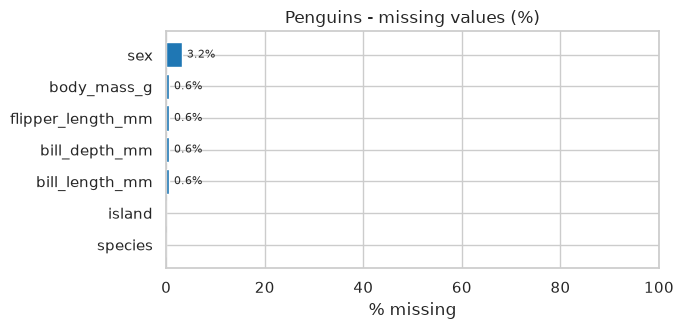

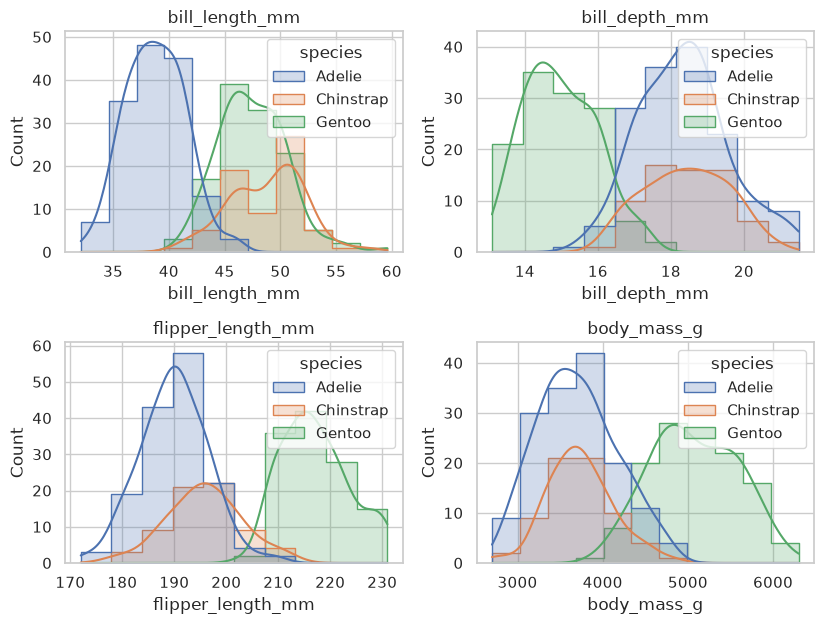

In [14]:
# The same utilities work unchanged on a different dataset: Palmer penguins.
penguins_raw = dskit.load("penguins")
fig = dskit.visualizer.plot_missing(penguins_raw, title="Penguins - missing values (%)")
plt.show()

fig = dskit.visualizer.plot_numeric_distributions(
    penguins_raw, columns=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"],
    hue="species", ncols=2,
)
plt.show()

Saved: figures/tips_tip_pct_by_day.png (23.1 KB)


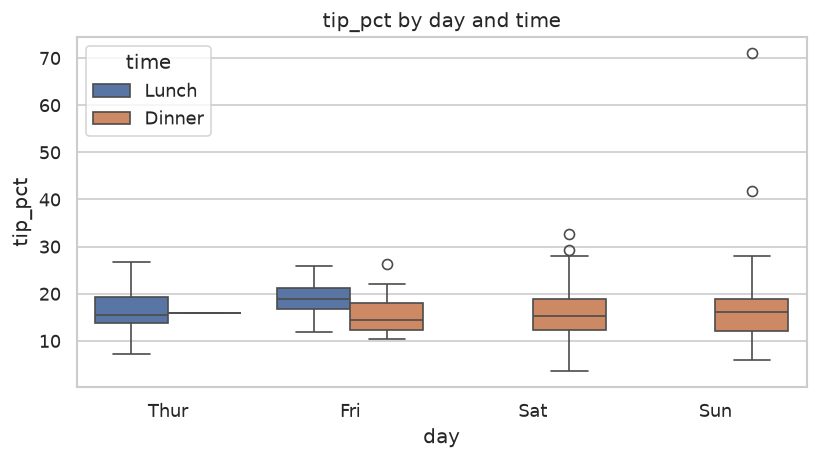

             count   mean  median
day  time                        
Thur Lunch      61  16.13   15.38
     Dinner      1  15.97   15.97
Fri  Lunch       7  18.88   18.77
     Dinner     12  15.89   14.48
Sat  Dinner     87  15.31   15.18
Sun  Dinner     76  16.69   16.11


In [15]:
# ... and on tips: the visualizer returns a Figure, so saving is a one-liner.
tips = dskit.load("tips")
tips["tip_pct"] = (tips["tip"] / tips["total_bill"] * 100).round(2)

fig = dskit.visualizer.plot_group_comparison(tips, x="day", y="tip_pct", hue="time", kind="box")
saved = dskit.visualizer.save_figure(fig, WORKSPACE / "figures" / "tips_tip_pct_by_day.png")
print("Saved:", saved.relative_to(WORKSPACE), f"({saved.stat().st_size / 1024:.1f} KB)")
display(Image(filename=str(saved), width=560))

print(tips.groupby(["day", "time"], observed=True)["tip_pct"].agg(["count", "mean", "median"]).round(2))

## Seção 4 — CLIs com `argparse` (biblioteca padrão)

Uma **CLI** (*command-line interface*) transforma o pacote numa ferramenta que roda fora do Jupyter — em *pipelines* de CI, agendadores (cron, Airflow) ou containers. O `argparse` não exige dependências e oferece:

- **argumentos posicionais** (`dataset`) e **opcionais** (`--by`, `--target`);
- `choices`, `type` (com validadores customizados), `nargs="+"`, `action="store_true"`;
- **subcomandos** (`dskit info ...`, `dskit groupby ...`) com `add_subparsers`;
- `--help` gerado automaticamente e `--version`.

Boas práticas que aplico: `main(argv=None) -> int` (testável sem subprocess), separar *parser* × lógica × saída, e **códigos de saída** (`0` = sucesso, `2` = erro de uso).

In [16]:
write_module("dskit/cli.py", '''
    """Command-line interface for dskit built with the standard-library argparse."""
    from __future__ import annotations

    import argparse
    import sys
    from collections.abc import Sequence

    import pandas as pd

    from ._version import __version__
    from .data_loader import SUPPORTED_DATASETS, dataset_summary, load

    AGGREGATIONS = ["mean", "median", "std", "min", "max", "count", "sum"]


    def _positive_int(value: str) -> int:
        """argparse ``type=`` validator: accept only integers > 0."""
        number = int(value)
        if number <= 0:
            raise argparse.ArgumentTypeError(f"expected a positive integer, got {value!r}")
        return number


    def build_parser() -> argparse.ArgumentParser:
        parser = argparse.ArgumentParser(
            prog="dskit",
            description="Quick, reproducible analysis of public seaborn datasets.",
            epilog="Example: dskit --format json groupby tips --by day --target tip --agg mean median",
        )
        parser.add_argument("--version", action="version", version=f"%(prog)s {__version__}")
        parser.add_argument("--format", choices=["table", "json", "csv"], default="table",
                            help="output format (default: %(default)s)")
        sub = parser.add_subparsers(dest="command", required=True, metavar="COMMAND")

        p_list = sub.add_parser("list", help="list the supported datasets")
        p_list.set_defaults(func=cmd_list)

        p_info = sub.add_parser("info", help="dtypes, missing values and cardinality")
        p_info.add_argument("dataset", choices=sorted(SUPPORTED_DATASETS))
        p_info.set_defaults(func=cmd_info)

        p_desc = sub.add_parser("describe", help="descriptive statistics of numeric columns")
        p_desc.add_argument("dataset", choices=sorted(SUPPORTED_DATASETS))
        p_desc.add_argument("-c", "--columns", nargs="+", metavar="COL", help="subset of columns")
        p_desc.add_argument("--dropna", action="store_true", help="drop rows with missing values")
        p_desc.set_defaults(func=cmd_describe)

        p_group = sub.add_parser("groupby", help="aggregate a numeric target by categorical columns")
        p_group.add_argument("dataset", choices=sorted(SUPPORTED_DATASETS))
        p_group.add_argument("--by", nargs="+", required=True, metavar="COL", help="grouping column(s)")
        p_group.add_argument("--target", required=True, help="numeric column to aggregate")
        p_group.add_argument("--agg", nargs="+", default=["mean"], choices=AGGREGATIONS,
                             help="aggregation(s) (default: mean)")
        p_group.add_argument("--top", type=_positive_int, metavar="N",
                             help="keep the N groups with the largest first aggregation")
        p_group.set_defaults(func=cmd_groupby)
        return parser


    def cmd_list(args: argparse.Namespace) -> pd.DataFrame:
        df = pd.DataFrame.from_dict(SUPPORTED_DATASETS, orient="index", columns=["description"])
        df.index.name = "dataset"
        return df


    def cmd_info(args: argparse.Namespace) -> pd.DataFrame:
        return dataset_summary(load(args.dataset))


    def cmd_describe(args: argparse.Namespace) -> pd.DataFrame:
        df = load(args.dataset, columns=args.columns, dropna=args.dropna)
        return df.describe().T


    def cmd_groupby(args: argparse.Namespace) -> pd.DataFrame:
        df = load(args.dataset)
        unknown = [c for c in [*args.by, args.target] if c not in df.columns]
        if unknown:
            raise KeyError(f"unknown column(s) {unknown}; available: {list(df.columns)}")
        if not pd.api.types.is_numeric_dtype(df[args.target]):
            raise TypeError(f"--target {args.target!r} must be numeric")
        result = df.groupby(args.by, observed=True)[args.target].agg(args.agg)
        if args.top:
            result = result.sort_values(args.agg[0], ascending=False).head(args.top)
        return result


    def emit(df: pd.DataFrame, fmt: str) -> None:
        """Render a DataFrame as an aligned table, JSON records or CSV."""
        if fmt == "json":
            print(df.reset_index().to_json(orient="records", indent=2))
        elif fmt == "csv":
            print(df.to_csv(), end="")
        else:
            print(df.round(3).to_string())


    def main(argv: Sequence[str] | None = None) -> int:
        """Entry point. ``argv=None`` reads ``sys.argv``; tests pass a list instead."""
        parser = build_parser()
        args = parser.parse_args(argv)
        try:
            result = args.func(args)
        except (KeyError, ValueError, TypeError) as exc:
            print(f"dskit: error: {exc}", file=sys.stderr)
            return 2
        emit(result, args.format)
        return 0


    if __name__ == "__main__":  # enables: python -m dskit.cli ...
        sys.exit(main())
''')

run([PY, "-m", "dskit.cli", "--help"]);

$ python -m dskit.cli --help


usage: dskit [-h] [--version] [--format {table,json,csv}] COMMAND ...

Quick, reproducible analysis of public seaborn datasets.

positional arguments:
  COMMAND
    list                list the supported datasets
    info                dtypes, missing values and cardinality
    describe            descriptive statistics of numeric columns
    groupby             aggregate a numeric target by categorical columns

options:
  -h, --help            show this help message and exit
  --version             show program's version number and exit
  --format {table,json,csv}
                        output format (default: table)

Example: dskit --format json groupby tips --by day --target tip --agg mean
median
[exit code: 0]



In [17]:
# Each sub-command gets its own help page.
run([PY, "-m", "dskit.cli", "groupby", "--help"]);

$ python -m dskit.cli groupby --help


usage: dskit groupby [-h] --by COL [COL ...] --target TARGET
                     [--agg {mean,median,std,min,max,count,sum} [{mean,median,std,min,max,count,sum} ...]]
                     [--top N]
                     {mpg,penguins,tips,titanic}

positional arguments:
  {mpg,penguins,tips,titanic}

options:
  -h, --help            show this help message and exit
  --by COL [COL ...]    grouping column(s)
  --target TARGET       numeric column to aggregate
  --agg {mean,median,std,min,max,count,sum} [{mean,median,std,min,max,count,sum} ...]
                        aggregation(s) (default: mean)
  --top N               keep the N groups with the largest first aggregation
[exit code: 0]



In [18]:
# How argparse turns a list of strings into a typed Namespace (no subprocess needed).
from dskit.cli import build_parser, main  # noqa: E402

args = build_parser().parse_args(["groupby", "tips", "--by", "day", "time", "--target", "tip", "--agg", "mean", "count"])
print(args)
print("args.by is a list :", args.by)
print("handler function  :", args.func.__name__)

Namespace(format='table', command='groupby', dataset='tips', by=['day', 'time'], target='tip', agg=['mean', 'count'], top=None, func=<function cmd_groupby at 0x707e8a09bc40>)
args.by is a list : ['day', 'time']
handler function  : cmd_groupby


In [19]:
# Real analyses from the terminal, on real datasets.
run([PY, "-m", "dskit.cli", "list"])
run([PY, "-m", "dskit.cli", "describe", "penguins", "-c", "bill_length_mm", "body_mass_g", "--dropna"])
run([PY, "-m", "dskit.cli", "groupby", "titanic", "--by", "class", "sex", "--target", "survived",
     "--agg", "mean", "count", "--top", "4"]);

$ python -m dskit.cli list


                                                description
dataset                                                    
titanic              Passenger survival on the RMS Titanic.
penguins           Palmer Archipelago penguin measurements.
tips      Restaurant bills and tips recorded by one waiter.
mpg               Fuel consumption of 1970-1982 car models.
[exit code: 0]

$ python -m dskit.cli describe penguins -c bill_length_mm body_mass_g --dropna


                count      mean      std     min       25%      50%     75%     max
bill_length_mm  342.0    43.922    5.460    32.1    39.225    44.45    48.5    59.6
body_mass_g     342.0  4201.754  801.955  2700.0  3550.000  4050.00  4750.0  6300.0
[exit code: 0]

$ python -m dskit.cli groupby titanic --by class sex --target survived --agg mean count --top 4


                mean  count
class  sex                 
First  female  0.968     94
Second female  0.921     76
Third  female  0.500    144
First  male    0.369    122
[exit code: 0]



In [20]:
# Machine-readable output: JSON can be piped into other tools (jq, APIs, dashboards).
result = run([PY, "-m", "dskit.cli", "--format", "json", "groupby", "tips", "--by", "day",
              "--target", "tip", "--agg", "mean", "median"], max_lines=8)
records = json.loads(result.stdout)
print("Parsed back into pandas:")
display(pd.DataFrame(records).round(3))

$ python -m dskit.cli --format json groupby tips --by day --target tip --agg mean median


[
  {
    "day":"Thur",
    "mean":2.7714516129,
    "median":2.305
  },
  {
    "day":"Fri",
... (14 more lines)
[exit code: 0]

Parsed back into pandas:


,day,mean,median
0,Thur,2.771,2.305
1,Fri,2.735,3.000
2,Sat,2.993,2.750
3,Sun,3.255,3.150


In [21]:
# Error handling and exit codes: invalid choice (argparse) vs. domain error (our code).
run([PY, "-m", "dskit.cli", "info", "iris"], check=False)
run([PY, "-m", "dskit.cli", "groupby", "tips", "--by", "day", "--target", "sex"], check=False)
run([PY, "-m", "dskit.cli", "groupby", "tips", "--by", "day", "--target", "tip", "--top", "0"], check=False)

# In-process call: main() returns the exit code, which is what the tests will assert.
print("main(['list']) returned:", main(["list"]))

$ python -m dskit.cli info iris


usage: dskit info [-h] {mpg,penguins,tips,titanic}
dskit info: error: argument dataset: invalid choice: 'iris' (choose from 'mpg', 'penguins', 'tips', 'titanic')
[exit code: 2]

$ python -m dskit.cli groupby tips --by day --target sex


dskit: error: --target 'sex' must be numeric
[exit code: 2]

$ python -m dskit.cli groupby tips --by day --target tip --top 0


usage: dskit groupby [-h] --by COL [COL ...] --target TARGET
                     [--agg {mean,median,std,min,max,count,sum} [{mean,median,std,min,max,count,sum} ...]]
                     [--top N]
                     {mpg,penguins,tips,titanic}
dskit groupby: error: argument --top: expected a positive integer, got '0'
[exit code: 2]

                                                description
dataset                                                    
titanic              Passenger survival on the RMS Titanic.
penguins           Palmer Archipelago penguin measurements.
tips      Restaurant bills and tips recorded by one waiter.
mpg               Fuel consumption of 1970-1982 car models.
main(['list']) returned: 0


## Seção 5 — Click: CLIs modernas com decorators

O **Click** (usado por Flask, Black, dbt e muitas ferramentas de dados) declara a CLI com **decorators** — algo que estudei no Dia 11:

| Decorator | Papel |
| --- | --- |
| `@click.group()` | Cria um comando "pai" com subcomandos (`dskit info`, `dskit plot`...) |
| `@click.command()` | Transforma uma função em comando |
| `@click.argument()` | Argumento posicional (obrigatório) |
| `@click.option()` | Opção nomeada: `type`, `default`, `multiple`, `required`, flags `--x/--no-x` |
| `@click.pass_context` | Compartilha estado (ex.: formato de saída) entre grupo e subcomandos |

Tipos ricos como `click.Choice`, `click.IntRange` e `click.Path` validam a entrada **antes** de chegar ao meu código, e `click.testing.CliRunner` permite testar a CLI sem subprocess.

In [22]:
write_module("dskit/cli_click.py", '''
    """Modern dskit CLI built with Click: groups, typed options and a plotting command."""
    from __future__ import annotations

    from pathlib import Path

    import click
    import pandas as pd

    from . import visualizer
    from ._version import __version__
    from .data_loader import SUPPORTED_DATASETS, dataset_summary, load

    DATASET = click.Choice(sorted(SUPPORTED_DATASETS), case_sensitive=False)
    AGGREGATIONS = ["mean", "median", "std", "min", "max", "count", "sum"]


    def _emit(df: pd.DataFrame, fmt: str) -> None:
        if fmt == "json":
            click.echo(df.reset_index().to_json(orient="records", indent=2))
        elif fmt == "csv":
            click.echo(df.to_csv(), nl=False)
        else:
            click.echo(df.round(3).to_string())


    @click.group(context_settings={"help_option_names": ["-h", "--help"]})
    @click.version_option(__version__, prog_name="dskit")
    @click.option("--format", "fmt", type=click.Choice(["table", "json", "csv"]),
                  default="table", show_default=True, help="Output format.")
    @click.pass_context
    def cli(ctx: click.Context, fmt: str) -> None:
        """Quick, reproducible analysis of public seaborn datasets."""
        ctx.ensure_object(dict)
        ctx.obj["fmt"] = fmt


    @cli.command("list")
    @click.pass_context
    def list_datasets(ctx: click.Context) -> None:
        """List the supported datasets."""
        df = pd.DataFrame.from_dict(SUPPORTED_DATASETS, orient="index", columns=["description"])
        _emit(df.rename_axis("dataset"), ctx.obj["fmt"])


    @cli.command()
    @click.argument("dataset", type=DATASET)
    @click.pass_context
    def info(ctx: click.Context, dataset: str) -> None:
        """Show dtypes, missing values and cardinality of DATASET."""
        _emit(dataset_summary(load(dataset)), ctx.obj["fmt"])


    @cli.command()
    @click.argument("dataset", type=DATASET)
    @click.option("-c", "--column", "columns", multiple=True, help="Column to keep (repeatable).")
    @click.option("--dropna/--keep-na", default=False, show_default=True,
                  help="Drop rows with missing values.")
    @click.pass_context
    def describe(ctx: click.Context, dataset: str, columns: tuple[str, ...], dropna: bool) -> None:
        """Descriptive statistics of the numeric columns of DATASET."""
        try:
            df = load(dataset, columns=columns or None, dropna=dropna)
        except KeyError as exc:
            raise click.BadParameter(str(exc), param_hint="--column") from exc
        _emit(df.describe().T, ctx.obj["fmt"])


    @cli.command()
    @click.argument("dataset", type=DATASET)
    @click.option("--by", multiple=True, required=True, help="Grouping column (repeatable).")
    @click.option("--target", required=True, help="Numeric column to aggregate.")
    @click.option("--agg", "aggs", multiple=True, type=click.Choice(AGGREGATIONS),
                  default=("mean",), show_default=True, help="Aggregation (repeatable).")
    @click.option("--top", type=click.IntRange(min=1), default=None,
                  help="Keep the N largest groups.")
    @click.pass_context
    def groupby(ctx: click.Context, dataset: str, by: tuple[str, ...], target: str,
                aggs: tuple[str, ...], top: int | None) -> None:
        """Aggregate TARGET by one or more categorical columns of DATASET."""
        df = load(dataset)
        unknown = [c for c in [*by, target] if c not in df.columns]
        if unknown:
            raise click.UsageError(f"unknown column(s) {unknown}; available: {list(df.columns)}")
        if not pd.api.types.is_numeric_dtype(df[target]):
            raise click.BadParameter(f"{target!r} is not numeric", param_hint="--target")
        result = df.groupby(list(by), observed=True)[target].agg(list(aggs))
        if top:
            result = result.sort_values(aggs[0], ascending=False).head(top)
        _emit(result, ctx.obj["fmt"])


    @cli.command()
    @click.argument("dataset", type=DATASET)
    @click.option("--x", "x_col", required=True, help="Categorical column (x axis).")
    @click.option("--y", "y_col", required=True, help="Numeric column (y axis).")
    @click.option("--hue", default=None, help="Optional column for colour.")
    @click.option("--kind", type=click.Choice(["box", "violin", "bar"]), default="box", show_default=True)
    @click.option("-o", "--output", type=click.Path(dir_okay=False, path_type=Path), required=True,
                  help="PNG file to write.")
    def plot(dataset: str, x_col: str, y_col: str, hue: str | None, kind: str, output: Path) -> None:
        """Save a group-comparison chart of DATASET to OUTPUT."""
        fig = visualizer.plot_group_comparison(load(dataset), x=x_col, y=y_col, hue=hue, kind=kind)
        path = visualizer.save_figure(fig, output)
        click.secho(f"Saved {path.name}", fg="green")


    def main() -> None:
        """Console-script entry point declared in pyproject.toml."""
        cli(obj={})


    if __name__ == "__main__":
        main()
''')

run([PY, "-m", "dskit.cli_click", "--help"]);

$ python -m dskit.cli_click --help


Usage: python -m dskit.cli_click [OPTIONS] COMMAND [ARGS]...

  Quick, reproducible analysis of public seaborn datasets.

Options:
  --version                  Show the version and exit.
  --format [table|json|csv]  Output format.  [default: table]
  -h, --help                 Show this message and exit.

Commands:
  describe  Descriptive statistics of the numeric columns of DATASET.
  groupby   Aggregate TARGET by one or more categorical columns of DATASET.
  info      Show dtypes, missing values and cardinality of DATASET.
  list      List the supported datasets.
  plot      Save a group-comparison chart of DATASET to OUTPUT.
[exit code: 0]



In [23]:
# Option help generated from the decorators (note show_default, multiple and the --dropna/--keep-na flag).
run([PY, "-m", "dskit.cli_click", "describe", "-h"])
run([PY, "-m", "dskit.cli_click", "--version"]);

$ python -m dskit.cli_click describe -h


Usage: python -m dskit.cli_click describe [OPTIONS]
                                          {mpg|penguins|tips|titanic}

  Descriptive statistics of the numeric columns of DATASET.

Options:
  -c, --column TEXT     Column to keep (repeatable).
  --dropna / --keep-na  Drop rows with missing values.  [default: keep-na]
  -h, --help            Show this message and exit.
[exit code: 0]

$ python -m dskit.cli_click --version


dskit, version 0.1.0
[exit code: 0]



In [24]:
# CliRunner invokes the CLI in-process: fast, captures output and exit code (ideal for tests).
from click.testing import CliRunner  # noqa: E402
from dskit.cli_click import cli  # noqa: E402

runner = CliRunner()
for argv in (
    ["groupby", "PENGUINS", "--by", "species", "--by", "sex", "--target", "body_mass_g", "--agg", "mean", "--agg", "count"],
    ["describe", "mpg", "-c", "mpg", "-c", "horsepower", "-c", "weight", "--dropna"],
    ["--format", "csv", "groupby", "titanic", "--by", "embark_town", "--target", "fare", "--agg", "median"],
):
    res = runner.invoke(cli, argv, obj={})
    print(f"$ dskit {' '.join(argv)}\n{res.output}[exit code: {res.exit_code}]\n")

$ dskit groupby PENGUINS --by species --by sex --target body_mass_g --agg mean --agg count
                      mean  count
species   sex                    
Adelie    Female  3368.836     73
          Male    4043.493     73
Chinstrap Female  3527.206     34
          Male    3938.971     34
Gentoo    Female  4679.741     58
          Male    5484.836     61
[exit code: 0]

$ dskit describe mpg -c mpg -c horsepower -c weight --dropna
            count      mean      std     min      25%      50%      75%     max
mpg         392.0    23.446    7.805     9.0    17.00    22.75    29.00    46.6
horsepower  392.0   104.469   38.491    46.0    75.00    93.50   126.00   230.0
weight      392.0  2977.584  849.403  1613.0  2225.25  2803.50  3614.75  5140.0
[exit code: 0]

$ dskit --format csv groupby titanic --by embark_town --target fare --agg median
embark_town,median
Cherbourg,29.7
Queenstown,7.75
Southampton,13.0
[exit code: 0]



In [25]:
# Validation happens in Click's type system, before our function runs.
for argv in (["info", "iris"], ["groupby", "tips", "--by", "day", "--target", "tip", "--top", "0"],
             ["groupby", "tips", "--by", "day", "--target", "smoker"]):
    res = runner.invoke(cli, argv, obj={})
    print(f"$ dskit {' '.join(argv)}\n{res.output.strip().splitlines()[-1]}\n[exit code: {res.exit_code}]\n")

$ dskit info iris
Error: Invalid value for '{mpg|penguins|tips|titanic}': 'iris' is not one of 'mpg', 'penguins', 'tips', 'titanic'.
[exit code: 2]

$ dskit groupby tips --by day --target tip --top 0
Error: Invalid value for '--top': 0 is not in the range x>=1.
[exit code: 2]

$ dskit groupby tips --by day --target smoker
Error: Invalid value for --target: 'smoker' is not numeric
[exit code: 2]



$ python -m dskit.cli_click plot titanic --x class --y age --hue survived --kind violin -o titanic_age_by_class.png


Saved titanic_age_by_class.png
[exit code: 0]



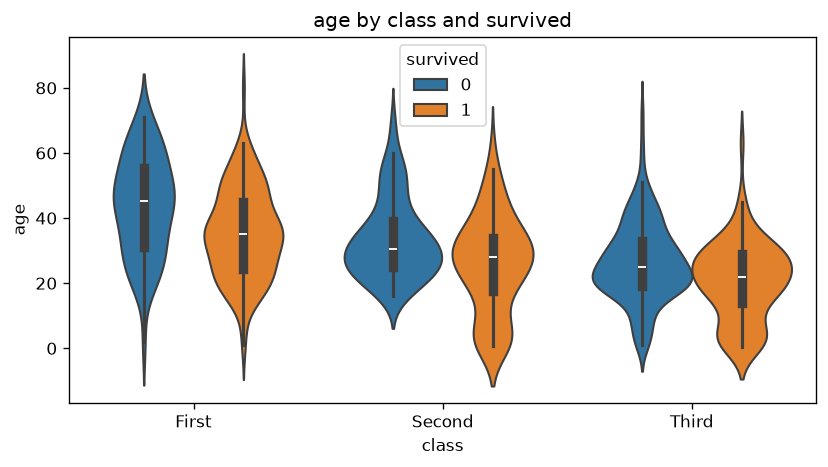

In [26]:
# The plot sub-command, executed as a real subprocess, writing a PNG from the titanic data.
png = WORKSPACE / "figures" / "titanic_age_by_class.png"
run([PY, "-m", "dskit.cli_click", "plot", "titanic", "--x", "class", "--y", "age",
     "--hue", "survived", "--kind", "violin", "-o", png])
display(Image(filename=str(png), width=560))

### `argparse` × `click` — quando usar cada um?

| Critério | `argparse` | `click` |
| --- | --- | --- |
| Dependências | Nenhuma (stdlib) | Pacote externo |
| Estilo | Imperativo (`add_argument`) | Declarativo (decorators) |
| Subcomandos | `add_subparsers` + `set_defaults(func=...)` | `@group` + `@group.command()` |
| Validação | `type=`, `choices=` | `Choice`, `IntRange`, `Path`, `File`... |
| Opções repetíveis | `nargs="+"` / `action="append"` | `multiple=True` |
| Testes | `main(argv)` + `capsys` | `CliRunner` |
| Melhor para | Scripts simples, zero dependências | Ferramentas com muitos comandos |

Minha regra prática: **script interno pequeno → `argparse`**; **ferramenta distribuída com vários subcomandos → `click`** (ou `typer`, que é construído sobre o Click e usa *type hints*).

## Seção 6 — Testes e distribuição do pacote

Um pacote só é reutilizável se for **confiável**. O fluxo profissional é:

1. **Testar** com `pytest` (Dia 10) — aqui usando o layout `src/` e `PYTHONPATH=src`.
2. **Instalar em modo editável** (`pip install -e .`, PEP 660): o ambiente aponta para o código-fonte, então edições aparecem sem reinstalar — ideal durante o desenvolvimento.
3. **Construir** os artefatos de distribuição com `python -m build`:
   - **sdist** (`.tar.gz`): o código-fonte + `pyproject.toml`;
   - **wheel** (`.whl`): um zip pronto para instalar, sem etapa de build.
4. **Publicar** (não executado aqui): `twine upload dist/*` para o PyPI/TestPyPI ou um índice privado.

In [27]:
write_module("tests/test_data_loader.py", '''
    import pandas as pd
    import pytest

    from dskit import SUPPORTED_DATASETS, dataset_summary, load


    @pytest.mark.parametrize("name", sorted(SUPPORTED_DATASETS))
    def test_every_supported_dataset_loads(name):
        df = load(name)
        assert isinstance(df, pd.DataFrame) and len(df) > 0


    def test_load_returns_independent_copies():
        first = load("tips")
        first.loc[0, "tip"] = -1
        assert load("tips").loc[0, "tip"] != -1


    def test_column_selection_and_dropna():
        df = load("penguins", columns=["species", "body_mass_g"], dropna=True)
        assert list(df.columns) == ["species", "body_mass_g"]
        assert not df.isna().any().any()


    @pytest.mark.parametrize("kwargs, error", [
        ({"name": "titanik"}, ValueError),
        ({"name": "tips", "columns": ["waiter"]}, KeyError),
    ])
    def test_invalid_inputs_fail_fast(kwargs, error):
        with pytest.raises(error):
            load(**kwargs)


    def test_dataset_summary_counts_missing_values():
        summary = dataset_summary(load("titanic"))
        assert summary.loc["deck", "n_missing"] > summary.loc["age", "n_missing"] > 0
''', root=PROJECT)

write_module("tests/test_preprocessor.py", '''
    import pandas as pd
    import pytest

    from dskit import TabularPreprocessor, clean_column_names, load


    def test_clean_column_names():
        df = pd.DataFrame(columns=["Body Mass (g)", "billLength", " species "])
        assert list(clean_column_names(df).columns) == ["body_mass_g", "bill_length", "species"]


    def test_transform_before_fit_raises():
        with pytest.raises(RuntimeError):
            TabularPreprocessor().transform(load("tips"))


    def test_no_missing_values_and_aligned_columns():
        titanic = load("titanic").drop(columns=["survived", "alive"])
        train, test = titanic.iloc[:600], titanic.iloc[600:]
        prep = TabularPreprocessor().fit(train)
        X_train, X_test = prep.transform(train), prep.transform(test)
        assert "deck" not in prep.columns_
        assert list(X_train.columns) == list(X_test.columns)
        assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0


    def test_statistics_learned_only_from_training_data():
        penguins = load("penguins")
        train = penguins[penguins["species"] == "Gentoo"]
        prep = TabularPreprocessor().fit(train)
        assert prep.numeric_fill_["body_mass_g"] == pytest.approx(train["body_mass_g"].median())
''', root=PROJECT)

write_module("tests/test_cli.py", '''
    import json

    from click.testing import CliRunner

    from dskit.cli import main
    from dskit.cli_click import cli


    def test_argparse_groupby_json(capsys):
        assert main(["--format", "json", "groupby", "tips", "--by", "day", "--target", "tip"]) == 0
        records = json.loads(capsys.readouterr().out)
        assert {r["day"] for r in records} == {"Thur", "Fri", "Sat", "Sun"}


    def test_argparse_domain_error_returns_2(capsys):
        assert main(["groupby", "tips", "--by", "day", "--target", "sex"]) == 2
        assert "must be numeric" in capsys.readouterr().err


    def test_click_groupby_and_validation():
        runner = CliRunner()
        ok = runner.invoke(cli, ["groupby", "penguins", "--by", "island", "--target", "body_mass_g"], obj={})
        assert ok.exit_code == 0 and "Biscoe" in ok.output
        bad = runner.invoke(cli, ["info", "iris"], obj={})
        assert bad.exit_code == 2


    def test_click_plot_writes_png(tmp_path):
        out = tmp_path / "plot.png"
        res = CliRunner().invoke(cli, ["plot", "tips", "--x", "day", "--y", "tip", "-o", str(out)], obj={})
        assert res.exit_code == 0 and out.stat().st_size > 0
''', root=PROJECT)

run([PY, "-m", "pytest", "-v", "--color=no", "-p", "no:cacheprovider"]);

$ python -m pytest -v --color=no -p no:cacheprovider


============================= test session starts ==============================
platform linux -- Python 3.11.17, pytest-9.2.0, pluggy-1.7.0
rootdir: /tmp/day18_packaging_c5qyngdv/dskit-project
configfile: pyproject.toml
testpaths: tests
plugins: platformdirs-4.14.0, anyio-4.15.1
collected 17 items

tests/test_cli.py ....                                                   [ 23%]
tests/test_data_loader.py .........                                      [ 76%]
tests/test_preprocessor.py ....                                          [100%]

============================== 17 passed in 1.20s ==============================
[exit code: 0]



In [28]:
# README is referenced by pyproject.toml (readme = "README.md"), so it must exist before building.
(PROJECT / "README.md").write_text(textwrap.dedent('''
    # dskit

    Reusable data-science utilities: dataset loading, leakage-safe preprocessing,
    plotting helpers and two CLIs (`dskit` with Click, `dskit-argparse` with argparse).

    ```bash
    pip install -e ".[dev]"
    dskit groupby tips --by day --target tip --agg mean --agg median
    ```
''').lstrip(), encoding="utf-8")

# Editable install inside a REAL, temporary virtual environment (the kernel env is untouched).
# --system-site-packages reuses pandas/seaborn/click/setuptools, so no download is needed.
VENV = WORKSPACE / ".venv"
venv.create(VENV, with_pip=True, system_site_packages=True)
VENV_BIN = VENV / ("Scripts" if os.name == "nt" else "bin")
VENV_PY = VENV_BIN / ("python.exe" if os.name == "nt" else "python")

run([VENV_PY, "-m", "pip", "install", "--no-deps", "--no-build-isolation", "--no-index", "-e", "."],
    pythonpath=False, max_lines=6);

$ python -m pip install --no-deps --no-build-isolation --no-index -e .


Obtaining file:///tmp/day18_packaging_c5qyngdv/dskit-project
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
... (7 more lines)
[exit code: 0]



In [29]:
# pythonpath=False: from now on dskit is found ONLY because it is installed in the venv.
run([VENV_PY, "-m", "pip", "show", "dskit"], pythonpath=False, max_lines=8)
run([VENV_PY, "-c", "import dskit, pathlib; print('imported from:', pathlib.Path(dskit.__file__).parent.relative_to(pathlib.Path.cwd()))"],
    pythonpath=False)

# [project.scripts] became real executables in the venv's bin/ folder.
run([VENV_BIN / "dskit", "groupby", "tips", "--by", "smoker", "--target", "tip", "--agg", "mean", "--agg", "count"],
    pythonpath=False)
run([VENV_BIN / "dskit-argparse", "--version"], pythonpath=False);

$ python -m pip show dskit


Name: dskit
Version: 0.1.0
Summary: Reusable data-science utilities: loading, preprocessing, plotting and CLIs.
Home-page: 
Author: Gutemberg Raposo
Author-email: 
License: 
Location: /tmp/day18_packaging_c5qyngdv/.venv/lib/python3.11/site-packages
... (3 more lines)
[exit code: 0]

$ python -c import dskit, pathlib; print('imported from:', pathlib.Path(dskit.__file__).parent.relative_to(pathlib.Path.cwd()))


imported from: src/dskit
[exit code: 0]

$ dskit groupby tips --by smoker --target tip --agg mean --agg count


         mean  count
smoker              
Yes     3.009     93
No      2.992    151
[exit code: 0]

$ dskit-argparse --version


dskit 0.1.0
[exit code: 0]



In [30]:
# "Editable" means: edit the source -> the installed package changes, no reinstall.
version_py = SRC / "dskit" / "_version.py"
original = version_py.read_text(encoding="utf-8")
version_py.write_text('__version__ = "0.1.1.dev0"\n', encoding="utf-8")
try:
    run([VENV_BIN / "dskit", "--version"], pythonpath=False)
    run([VENV_PY, "-c", "import importlib.metadata as m; print('installed metadata version:', m.version('dskit'))"],
        pythonpath=False)
finally:
    version_py.write_text(original, encoding="utf-8")  # always restore the file

$ dskit --version


dskit, version 0.1.1.dev0
[exit code: 0]

$ python -c import importlib.metadata as m; print('installed metadata version:', m.version('dskit'))
installed metadata version: 0.1.0
[exit code: 0]



> 💡 **Observação:** o `__version__` em tempo de execução mudou na hora, mas a versão nos **metadados instalados** continuou `0.1.0` — ela só é atualizada ao reinstalar. Por isso muitos projetos usam **uma única fonte de verdade** (ex.: `version = {attr = "dskit._version.__version__"}` com `dynamic = ["version"]`, ou `setuptools-scm` a partir das *tags* do Git).

In [31]:
# Build sdist + wheel. --no-isolation reuses the installed setuptools (offline-friendly);
# in CI you would normally run plain `python -m build` (isolated build env).
try:
    import build  # noqa: F401
    run([PY, "-m", "build", "--no-isolation", "--outdir", "dist"], pythonpath=False, max_lines=4)
except ImportError:
    print("`build` not installed -> falling back to `pip wheel` (wheel only).")
    run([PY, "-m", "pip", "wheel", ".", "--no-deps", "--no-build-isolation", "-w", "dist"], pythonpath=False, max_lines=4)

dist_files = sorted((PROJECT / "dist").iterdir())
for f in dist_files:
    print(f"{f.name:<35} {f.stat().st_size / 1024:6.1f} KB")

$ python -m build --no-isolation --outdir dist


running egg_info
creating src/dskit.egg-info
writing src/dskit.egg-info/PKG-INFO
writing dependency_links to src/dskit.egg-info/dependency_links.txt
... (109 more lines)
[exit code: 0]

dskit-0.1.0-py3-none-any.whl          10.1 KB
dskit-0.1.0.tar.gz                    10.0 KB


In [32]:
# A wheel is just a zip archive: inspect what will actually be installed.
wheel_path = next(f for f in dist_files if f.suffix == ".whl")
with zipfile.ZipFile(wheel_path) as whl:
    names = whl.namelist()
    print("Files inside the wheel:")
    for name in names:
        print("  ", name)
    dist_info = next(n.split("/")[0] for n in names if n.endswith(".dist-info/METADATA"))
    print("\nentry_points.txt:\n" + whl.read(f"{dist_info}/entry_points.txt").decode())
    metadata = whl.read(f"{dist_info}/METADATA").decode()
    print("METADATA (header):")
    print("\n".join(line for line in metadata.splitlines()[:40] if line.split(":")[0] in
                    {"Metadata-Version", "Name", "Version", "Summary", "License-Expression", "Requires-Python", "Requires-Dist", "Provides-Extra"}))

assert not any(n.startswith("tests/") for n in names), "tests must not be shipped inside the wheel"
print("\n✅ tests/ is not shipped; py.typed included:", any(n.endswith("py.typed") for n in names))

sdist = [f for f in dist_files if f.name.endswith(".tar.gz")]
if sdist:
    with tarfile.open(sdist[0]) as tar:
        print(f"sdist contains {len(tar.getnames())} entries, e.g.:", [n.split("/", 1)[-1] for n in tar.getnames()[:6]])

Files inside the wheel:
   dskit/__init__.py
   dskit/_version.py
   dskit/cli.py
   dskit/cli_click.py
   dskit/data_loader.py
   dskit/preprocessor.py
   dskit/py.typed
   dskit/visualizer.py
   dskit-0.1.0.dist-info/METADATA
   dskit-0.1.0.dist-info/WHEEL
   dskit-0.1.0.dist-info/entry_points.txt
   dskit-0.1.0.dist-info/top_level.txt
   dskit-0.1.0.dist-info/RECORD

entry_points.txt:
[console_scripts]
dskit = dskit.cli_click:main
dskit-argparse = dskit.cli:main

METADATA (header):
Metadata-Version: 2.4
Name: dskit
Version: 0.1.0
Summary: Reusable data-science utilities: loading, preprocessing, plotting and CLIs.
License-Expression: MIT
Requires-Python: >=3.10
Requires-Dist: pandas>=2.0
Requires-Dist: seaborn>=0.13
Requires-Dist: matplotlib>=3.7
Requires-Dist: click>=8.1
Provides-Extra: dev
Requires-Dist: pytest>=8; extra == "dev"
Requires-Dist: build>=1.0; extra == "dev"

✅ tests/ is not shipped; py.typed included: True
sdist contains 26 entries, e.g.: ['dskit-0.1.0', 'PKG-INFO', '

### Checklist de boas práticas de empacotamento

- ✅ **Layout `src/`** + `pyproject.toml` como fonte única de configuração.
- ✅ **API pública explícita** no `__init__.py` (`__all__`) e helpers privados com `_`.
- ✅ Dependências com **limites inferiores** no `pyproject.toml`; versões **travadas** ficam no *lock file* do aplicativo (Dia 15).
- ✅ Funções que **retornam** valores (DataFrames, Figures) em vez de imprimir/mostrar — mais fáceis de testar.
- ✅ CLIs com `main(argv) -> int`, mensagens de erro claras e **códigos de saída**.
- ✅ Testes rodando contra o pacote **instalado**; `tests/` fora do wheel.
- ✅ `py.typed` para distribuir as *type hints* (Dia 13).
- ✅ Versionamento semântico (`MAJOR.MINOR.PATCH`) e `CHANGELOG`.
- ⚠️ Antes de publicar no PyPI: testar no **TestPyPI**, conferir licença e nome disponível.

## Seção 7 — Aplicação em NLP/Educação: o pacote `nlp_edu`

Agora aplico tudo a uma área que conecta minha formação em **Linguística** com Data Science: um mini pacote para analisar a **dificuldade de textos em inglês** para aprendizes.

| Função | O que faz |
| --- | --- |
| `word_frequency()` | Frequência de palavras de conteúdo (sem *stopwords*), útil para listas de vocabulário |
| `readability_score()` | **Flesch Reading Ease** e **Flesch-Kincaid Grade Level**, com contagem heurística de sílabas |
| `cefr_classifier()` | Estimativa de nível **inspirada** no CEFR (A1–C2) a partir do *grade level* e da diversidade lexical |

> ⚠️ **Limite importante:** o `cefr_classifier` é uma **heurística didática**, não um nível CEFR oficial nem validado com aprendizes. Fórmulas de legibilidade foram calibradas para leitores nativos e para prosa moderna; textos poéticos, teatrais ou arcaicos as distorcem.

O pacote é **puro Python** (só `re`, `collections`, `math`), então não tem dependências obrigatórias — o NLTK entra só como fonte de dados.

In [33]:
NLP_PROJECT = WORKSPACE / "nlp-edu-project"
NLP_SRC = NLP_PROJECT / "src"

write_module("nlp_edu/text.py", r'''
    """Low-level text utilities: tokenisation, sentence splitting and syllable counting."""
    from __future__ import annotations

    import re

    __all__ = ["tokenize_words", "split_sentences", "count_syllables", "STOPWORDS"]

    _WORD_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
    # Break after . ! ? (optionally followed by a closing quote) + whitespace + capital/opening quote.
    _SENTENCE_RE = re.compile(r"(?:(?<=[.!?])|(?<=[.!?][\"']))\s+(?=[\"'A-Z])")

    STOPWORDS: frozenset[str] = frozenset("""
        a about above after again against all am an and any are as at be because been before being
        below between both but by can could did do does doing down during each few for from further
        had has have having he her here hers herself him himself his how i if in into is it its itself
        just me more most my myself no nor not now of off on once only or other our ours ourselves out
        over own same she should so some such than that the their theirs them themselves then there
        these they this those through to too under until up upon very was we were what when where which
        while who whom why will with would you your yours yourself yourselves shall said thou thee thy
        one mr mrs
    """.split())


    def tokenize_words(text: str, lower: bool = True) -> list[str]:
        """Alphabetic word tokens; keeps internal apostrophes (don't, Alice's)."""
        tokens = _WORD_RE.findall(text)
        return [t.lower() for t in tokens] if lower else tokens


    def split_sentences(text: str) -> list[str]:
        """Rule-based sentence splitter; also splits after quoted dialogue ending in . ! or ?."""
        normalised = re.sub(r"\s+", " ", text).strip()
        return [s for s in _SENTENCE_RE.split(normalised) if tokenize_words(s)]


    def count_syllables(word: str) -> int:
        """Heuristic English syllable count (vowel groups minus a silent final 'e')."""
        w = re.sub(r"[^a-z]", "", word.lower())
        if not w:
            return 0
        if len(w) <= 3:
            return 1
        w = re.sub(r"(?:[^laeiouy]es|[^laeiouy]ed|[^laeiouy]e)$", "", w)
        w = re.sub(r"^y", "", w)
        return max(1, len(re.findall(r"[aeiouy]{1,2}", w)))
''', root=NLP_SRC)

write_module("nlp_edu/metrics.py", '''
    """Corpus-level metrics for educational text analysis."""
    from __future__ import annotations

    from collections import Counter

    from .text import STOPWORDS, count_syllables, split_sentences, tokenize_words

    __all__ = ["word_frequency", "readability_score", "lexical_diversity"]


    def word_frequency(text: str, top_n: int | None = 20, *, min_length: int = 3,
                       remove_stopwords: bool = True) -> list[tuple[str, int]]:
        """Most frequent words, by default content words only (vocabulary-list candidates)."""
        tokens = [t for t in tokenize_words(text) if len(t) >= min_length]
        if remove_stopwords:
            tokens = [t for t in tokens if t not in STOPWORDS]
        return Counter(tokens).most_common(top_n)


    def lexical_diversity(text: str, window: int = 1000) -> float:
        """Moving-average type-token ratio (MATTR); robust to text length, unlike raw TTR."""
        tokens = tokenize_words(text)
        if not tokens:
            raise ValueError("text contains no words")
        if len(tokens) <= window:
            return len(set(tokens)) / len(tokens)
        counts = Counter(tokens[:window])
        ratios = [len(counts) / window]
        for i in range(window, len(tokens)):
            counts[tokens[i]] += 1
            old = tokens[i - window]
            counts[old] -= 1
            if counts[old] == 0:
                del counts[old]
            ratios.append(len(counts) / window)
        return sum(ratios) / len(ratios)


    def readability_score(text: str) -> dict[str, float]:
        """Flesch Reading Ease (higher = easier) and Flesch-Kincaid Grade Level (US school grade)."""
        words = tokenize_words(text)
        sentences = split_sentences(text)
        if not words or not sentences:
            raise ValueError("readability_score() needs at least one sentence with words")
        syllables = sum(count_syllables(w) for w in words)
        wps = len(words) / len(sentences)          # words per sentence
        spw = syllables / len(words)               # syllables per word
        return {
            "n_sentences": len(sentences),
            "n_words": len(words),
            "words_per_sentence": round(wps, 2),
            "syllables_per_word": round(spw, 3),
            "flesch_reading_ease": round(206.835 - 1.015 * wps - 84.6 * spw, 2),
            "fk_grade": round(0.39 * wps + 11.8 * spw - 15.59, 2),
        }
''', root=NLP_SRC)

print("text.py and metrics.py written")

text.py and metrics.py written


In [34]:
write_module("nlp_edu/cefr.py", '''
    """Heuristic, CEFR-INSPIRED difficulty bands (didactic; NOT official CEFR levels)."""
    from __future__ import annotations

    from .metrics import lexical_diversity, readability_score

    __all__ = ["CEFR_BANDS", "cefr_classifier"]

    # Upper bound of the adjusted grade for each band (illustrative thresholds).
    CEFR_BANDS: list[tuple[str, float]] = [
        ("A1", 2.0), ("A2", 4.0), ("B1", 6.0), ("B2", 8.5), ("C1", 11.0), ("C2", float("inf")),
    ]


    def cefr_classifier(text: str, diversity_weight: float = 10.0) -> dict[str, object]:
        """Estimate a CEFR-like band from syntactic (grade) and lexical (MATTR) difficulty.

        adjusted_grade = fk_grade + diversity_weight * (MATTR - 0.40)
        A MATTR of 0.40 is treated as neutral; richer vocabulary pushes the text upwards.
        """
        scores = readability_score(text)
        mattr = lexical_diversity(text)
        adjusted = scores["fk_grade"] + diversity_weight * (mattr - 0.40)
        level = next(band for band, upper in CEFR_BANDS if adjusted <= upper)
        return {
            "level": level,
            "adjusted_grade": round(adjusted, 2),
            "fk_grade": scores["fk_grade"],
            "mattr": round(mattr, 3),
            "disclaimer": "heuristic estimate, not an official CEFR assessment",
        }
''', root=NLP_SRC)

write_module("nlp_edu/cli.py", '''
    """nlp-edu: profile the difficulty of an English text from the terminal."""
    from __future__ import annotations

    import argparse
    import json
    import sys
    from collections.abc import Sequence
    from pathlib import Path

    from . import __version__
    from .cefr import cefr_classifier
    from .metrics import readability_score, word_frequency


    def _read_text(args: argparse.Namespace) -> str:
        if args.gutenberg:
            from nltk.corpus import gutenberg  # optional dependency, imported lazily
            return gutenberg.raw(args.gutenberg)
        if args.file == "-":
            return sys.stdin.read()
        return Path(args.file).read_text(encoding="utf-8")


    def main(argv: Sequence[str] | None = None) -> int:
        parser = argparse.ArgumentParser(prog="nlp-edu", description="Readability, vocabulary and CEFR-like profile of a text.")
        source = parser.add_mutually_exclusive_group(required=True)
        source.add_argument("file", nargs="?", help="UTF-8 text file ('-' for stdin)")
        source.add_argument("--gutenberg", metavar="FILEID", help="NLTK Gutenberg file id, e.g. carroll-alice.txt")
        parser.add_argument("--top", type=int, default=10, help="number of frequent words (default: %(default)s)")
        parser.add_argument("--json", action="store_true", help="print a JSON report")
        parser.add_argument("--version", action="version", version=f"%(prog)s {__version__}")
        args = parser.parse_args(argv)
        try:
            text = _read_text(args)
            report = {"readability": readability_score(text), "cefr_like": cefr_classifier(text),
                      "top_words": word_frequency(text, args.top)}
        except (OSError, ValueError, LookupError) as exc:
            print(f"nlp-edu: error: {exc}", file=sys.stderr)
            return 1
        if args.json:
            print(json.dumps(report, indent=2))
        else:
            r, c = report["readability"], report["cefr_like"]
            print(f"Words: {r['n_words']:,} | Sentences: {r['n_sentences']:,} | Words/sentence: {r['words_per_sentence']}")
            print(f"Flesch Reading Ease: {r['flesch_reading_ease']} | FK grade: {r['fk_grade']}")
            print(f"CEFR-like band: {c['level']} (adjusted grade {c['adjusted_grade']}, MATTR {c['mattr']}) - {c['disclaimer']}")
            print("Top words:", ", ".join(f"{w} ({n})" for w, n in report["top_words"]))
        return 0


    if __name__ == "__main__":
        sys.exit(main())
''', root=NLP_SRC)

write_module("nlp_edu/__init__.py", '''
    """nlp_edu - pure-Python text-difficulty tools for English language education."""
    __version__ = "0.1.0"

    from .cefr import cefr_classifier
    from .metrics import lexical_diversity, readability_score, word_frequency
    from .text import count_syllables, split_sentences, tokenize_words

    __all__ = ["__version__", "word_frequency", "readability_score", "lexical_diversity",
               "cefr_classifier", "tokenize_words", "split_sentences", "count_syllables"]
''', root=NLP_SRC)

(NLP_PROJECT / "pyproject.toml").write_text(textwrap.dedent('''
    [build-system]
    requires = ["setuptools>=77"]
    build-backend = "setuptools.build_meta"

    [project]
    name = "nlp-edu"                     # distribution name uses a hyphen...
    version = "0.1.0"
    description = "Pure-Python readability and vocabulary profiling for English learners."
    requires-python = ">=3.10"
    license = "MIT"
    dependencies = []                    # ...import name (nlp_edu) uses an underscore

    [project.optional-dependencies]
    corpora = ["nltk>=3.8"]

    [project.scripts]
    nlp-edu = "nlp_edu.cli:main"

    [tool.setuptools.packages.find]
    where = ["src"]
''').lstrip(), encoding="utf-8")

show_tree(NLP_PROJECT)

nlp-edu-project/
├── src/
│   └── nlp_edu/
│       ├── __init__.py
│       ├── cefr.py
│       ├── cli.py
│       ├── metrics.py
│       └── text.py
└── pyproject.toml


In [35]:
sys.path.insert(0, str(NLP_SRC))
import nlp_edu  # noqa: E402

# Unit-level sanity checks of the syllable heuristic (known English words).
expected = {"cat": 1, "simple": 2, "reading": 2, "elephant": 3, "education": 4, "language": 2}
got = {w: nlp_edu.count_syllables(w) for w in expected}
print("Syllables:", got)
print("Agreement with dictionary counts:", sum(got[w] == n for w, n in expected.items()), "/", len(expected))

# Load the real corpus: NLTK's Project Gutenberg selection (public-domain texts).
import nltk  # noqa: E402
from nltk.corpus import gutenberg  # noqa: E402

try:
    gutenberg.fileids()
except LookupError:
    nltk.download("gutenberg", quiet=True)

alice = gutenberg.raw("carroll-alice.txt")
print(f"\ncarroll-alice.txt: {len(alice):,} characters")
print("First sentences:", nlp_edu.split_sentences(alice[1000:1600])[:2])

Syllables: {'cat': 1, 'simple': 2, 'reading': 2, 'elephant': 3, 'education': 4, 'language': 2}
Agreement with dictionary counts: 6 / 6

carroll-alice.txt: 144,395 characters
First sentences: ['when the Rabbit actually TOOK A WATCH OUT OF ITS WAISTCOAT-POCKET, and looked at it, and then hurried on, Alice started to her feet, for it flashed across her mind that she had never before seen a rabbit with either a waistcoat-pocket, or a watch to take out of it, and burning with curiosity, she ran across the field after it, and fortunately was just in time to see it pop down a large rabbit-hole under the hedge.', 'In another moment down went Alice after it, never once considering how in the world she was to get out again.']


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
word,alice,little,know,like,went,thought,time,queen,see,well,don't,king,i'm,began,it's
count,386,128,88,85,83,74,71,68,67,63,61,61,59,58,57
per_10k_words,144.6,48.0,33.0,31.9,31.1,27.7,26.6,25.5,25.1,23.6,22.9,22.9,22.1,21.7,21.4


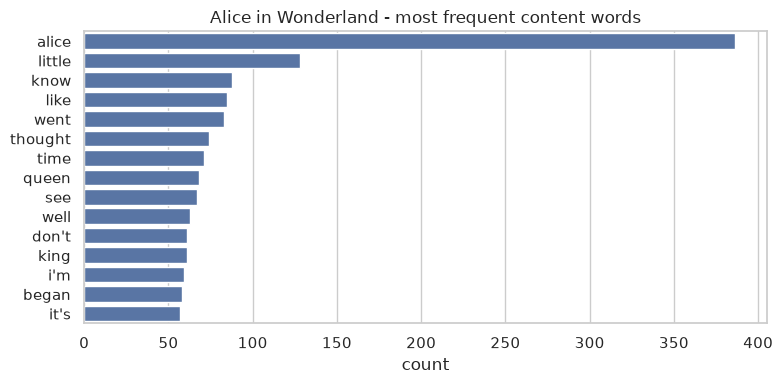

In [36]:
# word_frequency(): candidate vocabulary for a graded-reader activity based on 'Alice'.
top_alice = pd.DataFrame(nlp_edu.word_frequency(alice, top_n=15), columns=["word", "count"])
top_alice["per_10k_words"] = (top_alice["count"] / len(nlp_edu.tokenize_words(alice)) * 10_000).round(1)
display(top_alice.T)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=top_alice, x="count", y="word", color="#4c72b0", ax=ax)
ax.set(title="Alice in Wonderland - most frequent content words", xlabel="count", ylabel="")
fig.tight_layout()
plt.show()

In [37]:
# readability_score() + cefr_classifier() across texts of very different difficulty.
TEXTS = {
    "burgess-busterbrown.txt": "Children's story",
    "bryant-stories.txt": "Stories for children",
    "carroll-alice.txt": "Children's novel",
    "chesterton-thursday.txt": "Adult novel",
    "austen-emma.txt": "Adult novel",
    "melville-moby_dick.txt": "Adult novel",
    "shakespeare-caesar.txt": "Play (verse)",
}

rows = []
for fileid, genre in TEXTS.items():
    text = gutenberg.raw(fileid)
    rows.append({"text": fileid.removesuffix(".txt"), "genre": genre,
                 **nlp_edu.readability_score(text),
                 **{k: v for k, v in nlp_edu.cefr_classifier(text).items() if k != "disclaimer"}})

# Both dicts contain the same "fk_grade" key/value, so the merge keeps a single column.
profile = (pd.DataFrame(rows).rename(columns={"level": "cefr_like"})
           .sort_values("adjusted_grade").reset_index(drop=True))
display(profile[["text", "genre", "n_words", "words_per_sentence", "syllables_per_word",
                 "flesch_reading_ease", "fk_grade", "mattr", "adjusted_grade", "cefr_like"]])

,text,genre,n_words,words_per_sentence,syllables_per_word,flesch_reading_ease,fk_grade,mattr,adjusted_grade,cefr_like
0,shakespeare-caesar,Play (verse),20461,12.99,1.292,84.32,4.73,0.404,4.77,B1
1,burgess-busterbrown,Children's story,15963,16.58,1.248,84.42,5.60,0.331,4.91,B1
2,bryant-stories,Stories for children,46319,18.69,1.247,82.40,6.41,0.336,5.77,B1
3,carroll-alice,Children's novel,26687,20.47,1.281,77.67,7.51,0.369,7.20,B2
4,chesterton-thursday,Adult novel,58295,16.86,1.370,73.85,7.15,0.430,7.45,B2
5,austen-emma,Adult novel,160994,18.58,1.385,70.81,8.00,0.398,7.98,B2
6,melville-moby_dick,Adult novel,215970,24.40,1.396,63.94,10.40,0.469,11.09,C2


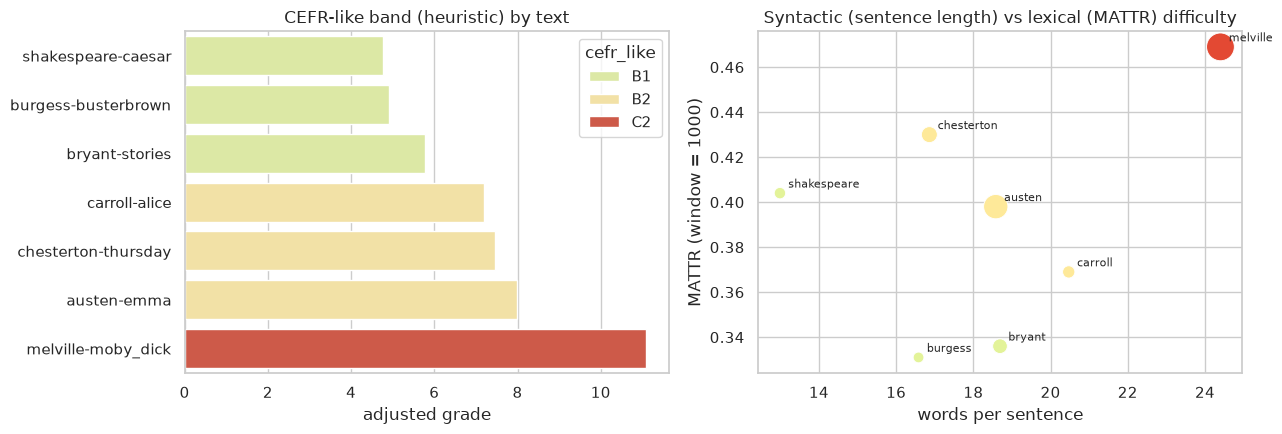

In [38]:
order = profile["text"].tolist()
palette = dict(zip(["A1", "A2", "B1", "B2", "C1", "C2"], sns.color_palette("RdYlGn_r", 6)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=profile, y="text", x="adjusted_grade", hue="cefr_like", palette=palette,
            order=order, dodge=False, ax=axes[0])
axes[0].set(title="CEFR-like band (heuristic) by text", xlabel="adjusted grade", ylabel="")
sns.scatterplot(data=profile, x="words_per_sentence", y="mattr", hue="cefr_like", palette=palette,
                size="n_words", sizes=(60, 400), ax=axes[1], legend=False)
for _, r in profile.iterrows():
    axes[1].annotate(r["text"].split("-")[0], (r["words_per_sentence"], r["mattr"]),
                     textcoords="offset points", xytext=(6, 4), fontsize=8)
axes[1].set(title="Syntactic (sentence length) vs lexical (MATTR) difficulty",
            xlabel="words per sentence", ylabel="MATTR (window = 1000)")
fig.tight_layout()
plt.show()

### Interpretação linguística

- Entre os textos em prosa, os infantis (Burgess, Bryant) ficam na faixa mais baixa: frases mais curtas e vocabulário repetitivo (MATTR ≈ 0,33) — o que se espera de leituras para crianças.
- *Alice* fica acima deles: é um livro infantil, mas com frases longas e muito diálogo encadeado — e escrito para leitores **nativos**, não para aprendizes.
- *Moby Dick* chega ao topo por dois caminhos ao mesmo tempo: **frases longas** (sintaxe) e o **vocabulário mais variado** do conjunto (léxico). Separar as duas dimensões ajuda o professor a escolher *que tipo* de apoio oferecer.
- *Júlio César* aparece como o texto "mais fácil", o que é claramente um **artefato**: em verso/teatro, cada fala curta vira uma "frase", e a fórmula **subestima** a dificuldade real do inglês elisabetano. É um bom lembrete sociolinguístico: **registro e gênero** importam tanto quanto métricas superficiais.
- O divisor de frases é baseado em regras (pontuação + maiúscula); abreviações como "Mr." ou cabeçalhos de capítulo introduzem ruído nas contagens.
- Por isso o pacote rotula o resultado como *CEFR-like* e carrega um `disclaimer` — uma boa prática de **comunicação honesta** de modelos.

In [39]:
# Package the nlp_edu project, test it, install the wheel in the venv and use its console script.
write_module("tests/test_nlp_edu.py", '''
    import pytest

    from nlp_edu import cefr_classifier, count_syllables, readability_score, split_sentences, word_frequency


    @pytest.mark.parametrize("word, n", [("cat", 1), ("simple", 2), ("elephant", 3), ("", 0)])
    def test_count_syllables(word, n):
        assert count_syllables(word) == n


    def test_split_sentences_and_frequency():
        text = "The cat sat. The cat ran! Did the dog run?"
        assert len(split_sentences(text)) == 3
        assert word_frequency(text, top_n=1) == [("cat", 2)]


    def test_short_simple_text_is_easier_than_long_complex_text():
        easy = "I see a cat. The cat is red. I like the cat."
        hard = ("Notwithstanding considerable methodological heterogeneity, contemporary sociolinguistic "
                "investigations systematically demonstrate that institutional evaluations of linguistic "
                "variation reproduce hierarchical ideologies concerning legitimacy and prestige.")
        assert readability_score(easy)["fk_grade"] < readability_score(hard)["fk_grade"]
        assert cefr_classifier(easy)["level"] < cefr_classifier(hard)["level"]


    def test_empty_text_raises():
        with pytest.raises(ValueError):
            readability_score("   ")
''', root=NLP_PROJECT)

run([PY, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "tests"], cwd=NLP_PROJECT, pythonpath=NLP_SRC)

run([PY, "-m", "pip", "wheel", ".", "--no-deps", "--no-build-isolation", "-w", "dist"],
    cwd=NLP_PROJECT, pythonpath=False, max_lines=3)
nlp_wheel = next((NLP_PROJECT / "dist").glob("*.whl"))
run([VENV_PY, "-m", "pip", "install", "--no-deps", "--no-index", nlp_wheel], pythonpath=False, max_lines=3);

$ python -m pytest -q --color=no -p no:cacheprovider tests


.......                                                                  [100%]
7 passed in 0.01s
[exit code: 0]

$ python -m pip wheel . --no-deps --no-build-isolation -w dist


Processing ./.
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
... (6 more lines)
[exit code: 0]

$ python -m pip install --no-deps --no-index nlp_edu-0.1.0-py3-none-any.whl


Processing /tmp/day18_packaging_c5qyngdv/nlp-edu-project/dist/nlp_edu-0.1.0-py3-none-any.whl
[exit code: 0]



In [40]:
# The installed console script, used on a Gutenberg text and on a plain-text file.
run([VENV_BIN / "nlp-edu", "--gutenberg", "bryant-stories.txt", "--top", "8"], pythonpath=False)

sample_file = WORKSPACE / "persuasion_ch1.txt"
persuasion = gutenberg.raw("austen-persuasion.txt")
sample_file.write_text(persuasion[: persuasion.find("Chapter 2")], encoding="utf-8")
result = run([VENV_BIN / "nlp-edu", sample_file, "--json", "--top", "5"], pythonpath=False, max_lines=12)
print("Parsed CEFR-like band from JSON:", json.loads(result.stdout)["cefr_like"]["level"])

$ nlp-edu --gutenberg bryant-stories.txt --top 8


Words: 46,319 | Sentences: 2,478 | Words/sentence: 18.69
Flesch Reading Ease: 82.4 | FK grade: 6.41
CEFR-like band: B1 (adjusted grade 5.77, MATTR 0.336) - heuristic estimate, not an official CEFR assessment
Top words: little (598), came (191), king (125), went (122), great (110), day (106), old (104), time (97)
[exit code: 0]

$ nlp-edu persuasion_ch1.txt --json --top 5
{
  "readability": {
    "n_sentences": 69,
    "n_words": 2614,
    "words_per_sentence": 37.88,
    "syllables_per_word": 1.488,
    "flesch_reading_ease": 42.52,
    "fk_grade": 16.74
  },
  "cefr_like": {
    "level": "C2",
    "adjusted_grade": 16.97,
... (27 more lines)
[exit code: 0]

Parsed CEFR-like band from JSON: C2


In [41]:
# Final view of everything this notebook produced (the .venv folder is hidden).
show_tree(WORKSPACE)

day18_packaging_c5qyngdv/
├── dskit-project/
│   ├── dist/
│   │   ├── dskit-0.1.0-py3-none-any.whl
│   │   └── dskit-0.1.0.tar.gz
│   ├── src/
│   │   └── dskit/
│   │       ├── __init__.py
│   │       ├── _version.py
│   │       ├── cli.py
│   │       ├── cli_click.py
│   │       ├── data_loader.py
│   │       ├── preprocessor.py
│   │       ├── py.typed
│   │       └── visualizer.py
│   ├── tests/
│   │   ├── test_cli.py
│   │   ├── test_data_loader.py
│   │   └── test_preprocessor.py
│   ├── README.md
│   └── pyproject.toml
├── figures/
│   ├── tips_tip_pct_by_day.png
│   └── titanic_age_by_class.png
├── nlp-edu-project/
│   ├── dist/
│   │   └── nlp_edu-0.1.0-py3-none-any.whl
│   ├── src/
│   │   └── nlp_edu/
│   │       ├── __init__.py
│   │       ├── cefr.py
│   │       ├── cli.py
│   │       ├── metrics.py
│   │       └── text.py
│   ├── tests/
│   │   └── test_nlp_edu.py
│   └── pyproject.toml
├── section1/
│   └── minipkg/
│       ├── metrics/
│       │   ├── __init__.py
│   

## Conclusão — 🏁 Fase 1 concluída!

Hoje eu fechei o ciclo "notebook → pacote → ferramenta":

- **Seção 1:** pacotes, subpacotes, `__init__.py`, `__all__`, imports relativos, `sys.modules` e `importlib.reload`.
- **Seção 2:** `pyproject.toml` completo — `[build-system]`, `[project]`, extras, `[project.scripts]` e `[tool.*]` — validado com `tomllib`.
- **Seção 3:** `dskit` com `data_loader` (cache + validação), `preprocessor` (fit/transform sem vazamento) e `visualizer` (funções que retornam `Figure`), aplicados a `titanic`, `penguins` e `tips`.
- **Seções 4 e 5:** a mesma CLI em `argparse` e em `click`, com subcomandos, validação, saída JSON/CSV e códigos de saída.
- **Seção 6:** testes com `pytest`, `pip install -e .` num *venv* real, executáveis gerados pelos entry points e *sdist*/*wheel* com `python -m build`.
- **Seção 7:** `nlp_edu`, um pacote de NLP educacional com frequência de palavras, legibilidade e bandas *CEFR-like*, aplicado ao corpus Gutenberg do NLTK.

### Os 18 tópicos da Fase 1 — Python Basics

| Dia | Tópico | Dia | Tópico |
| --- | --- | --- | --- |
| 1 | pandas | 10 | Testes com `pytest` |
| 2 | NumPy | 11 | Decorators e context managers |
| 3 | Matplotlib & Seaborn | 12 | `itertools` & `functools` |
| 4 | Funções e comprehensions | 13 | `typing` e type hints |
| 5 | Strings & regex | 14 | Concorrência e pipelines paralelos |
| 6 | File I/O | 15 | Gerenciamento de ambientes |
| 7 | Programação orientada a objetos | 16 | Logging & debugging |
| 8 | Plotly | 17 | Profiling & otimização de performance |
| 9 | datetime & séries temporais no pandas | **18** | **Empacotamento & módulos reutilizáveis** |

### O que levo para a Fase 2 (Análise Exploratória de Dados)
- Reutilizar `dskit`/`nlp_edu` como base: cada nova análise deve virar **função testada**, não célula copiada.
- Manter o hábito de **dados reais**, **validação explícita** e **limites declarados** (como o *disclaimer* do CEFR-like).
- Conectar cada vez mais Linguística, Data Science e NLP aplicado ao ensino de inglês.

> **Próximo passo:** Fase 2 — EDA, começando com perfis de dados sistemáticos e perguntas de pesquisa bem formuladas.